In [15]:
import pyreadstat
import pandas as pd

path = r"O:\Projecten lopend\BW & kansengelijkheid\Data\Werkbestand BW en kansengelijkheid.sav"

def load_and_label(path):
    df, meta = pyreadstat.read_sav(path)

    # Decode gemcode2021 into an unambiguous, panel-specific gemeente column
    # BEFORE renaming/concatenating, using this file's own codebook
    if 'gemcode2021' in df.columns and 'gemcode2021' in meta.variable_value_labels:
        df['gemeente'] = df['gemcode2021'].map(meta.variable_value_labels['gemcode2021'])

    # Rename other columns to their labels
    label_map = {c: l for c, l in zip(meta.column_names, meta.column_labels) if l}
    df.rename(columns=label_map, inplace=True)

    # Apply value labels for all other labeled columns
    for col_original, col_renamed in label_map.items():
        if col_original == 'gemcode2021':
            continue  # already handled above as 'gemeente'
        if col_original in meta.variable_value_labels:
            value_map = meta.variable_value_labels[col_original]
            df[col_renamed] = df[col_renamed].map(value_map).fillna(df[col_renamed])

    # â”€â”€ Check for duplicate column names after renaming â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    dupes = df.columns[df.columns.duplicated()].unique()
    if len(dupes) > 0:
        print(f"  !! {path.split(chr(92))[-1]}: {len(dupes)} duplicate kolomnamen -> {list(dupes)}")
        # Disambiguate: keep first occurrence name, suffix the rest
        cols = pd.Series(df.columns)
        for dup in cols[cols.duplicated()].unique():
            idxs = cols[cols == dup].index
            for i, idx in enumerate(idxs):
                if i > 0:
                    cols[idx] = f"{dup}__{i+1}"
        df.columns = cols

    df["_bronbestand"] = path.split("\\")[-1]
    return df

df = load_and_label(path) 



  !! Werkbestand BW en kansengelijkheid.sav: 1 duplicate kolomnamen -> ['Jaar']


In [16]:
combined = df.copy()

combined = combined[combined['Reactiestatus'] != 'Niet geantwoord']
df = combined  # sync: zorg dat df en combined dezelfde gefilterde dataset zijn
print(f"\nCombined shape na Reactiestatus filter: {combined.shape}")


Combined shape na Reactiestatus filter: (3737, 269)


In [17]:
# Hernoem korte SPSS-codes naar leesbare namen voor gebruik in analyses/grafieken
rename_map = {}
_rename_candidates = {
    "opleiding3":                                       "Opleiding (3 niveaus)",
    "Inkomencat":                                       "Inkomen (categorie)",
    "Woont u in een koopwoning of huurwoning?":         "Koop of huurwoning",
    "leefcat":                                          "leeftijd categorie",
    "Provincie":                                        "regioprovincie",
}
for orig, kort in _rename_candidates.items():
    if orig in df.columns:
        rename_map[orig] = kort
df.rename(columns=rename_map, inplace=True)
combined = df  # blijf gesynchroniseerd
print("Hernoemde kolommen:", list(rename_map.values()))

Hernoemde kolommen: ['Opleiding (3 niveaus)', 'Inkomen (categorie)', 'Koop of huurwoning', 'leeftijd categorie', 'regioprovincie']


In [18]:
combined.head()

,Voornaam,Reactiestatus,regioprovincie,Jaar,Wat is uw postcode? (bv. 9640 PA)<br>\n<br>\n<em>Let op: 4 cijfers gevolgd door spatie en 2 hoofdletters</em>,Jaar__2,Leeftijd,leeftijd categorie,leefcat_weging,Opleiding (3 niveaus),...,Welke van de volgende situaties is op u van toepassing? (Meerdere antwoorden mogelijk) - Ik heb vaak moeite met het bereiken van belangrijke plekken,Welke van de volgende situaties is op u van toepassing? (Meerdere antwoorden mogelijk) - Ik voel me niet om mijn gemak in de buurt waarin ik woon,Welke van de volgende situaties is op u van toepassing? (Meerdere antwoorden mogelijk) - Ik ben regelmatig bang om in onveilige situaties terecht te komen,Welke van de volgende situaties is op u van toepassing? (Meerdere antwoorden mogelijk) - Ik maak me regelmatig zorgen om het milieu of de omgeving (bijvoorbeeld overstromingen of aardbevingen),Welke van de volgende situaties is op u van toepassing? (Meerdere antwoorden mogelijk) - Geen van bovenstaande situaties,Welke van de volgende situaties is op u van toepassing? (Meerdere antwoorden mogelijk) - Wil ik niet zeggen,Konden uw ouders of verzorgers over het algemeen goed rondkomen toen u kind was?,Hadden uw ouders of verzorgers voldoende tijd en aandacht voor u toen u kind was?,Kon u als volwassene (vanaf 25 jaar) meestal goed rondkomen?,_bronbestand
0,ff692ac2-37d7-4eb7-bd9e-56830aba3858,Compleet,Groningen,2026,9933AA,1943.0,82.0,65 en ouder,65 en ouder,laag,...,0.0,0.0,0.0,0.0,1.0,0.0,Weet ik niet/ Wil ik niet zeggen,Altijd,Altijd,Werkbestand BW en kansengelijkheid.sav
1,5afaedf9-c590-4b23-a1df-9cc229425111,Compleet,Drenthe,2026,7944PB,1953.0,72.0,65 en ouder,65 en ouder,laag,...,0.0,0.0,1.0,0.0,0.0,0.0,Ze konden met moeite rondkomen,Meestal,Meestal,Werkbestand BW en kansengelijkheid.sav
2,f82664a1-3858-42a0-9b14-7eee24e3affa,Compleet,Drenthe,2026,7961LJ,1942.0,83.0,65 en ouder,65 en ouder,hoog,...,0.0,0.0,0.0,0.0,1.0,0.0,Ze konden makkelijk rondkomen,Weet ik niet/ Wil ik niet zeggen,Meestal,Werkbestand BW en kansengelijkheid.sav
3,f73a2a6f-3444-4c01-8045-6ba2ac0158b8,Compleet,Groningen,2026,9679HZ,1937.0,88.0,65 en ouder,65 en ouder,hoog,...,0.0,0.0,0.0,1.0,0.0,0.0,Ze konden met moeite rondkomen,Soms,Meestal,Werkbestand BW en kansengelijkheid.sav
4,0718a9a6-7708-4365-9628-95b17092e0ef,Compleet,Drenthe,2026,7941KC,1956.0,69.0,65 en ouder,65 en ouder,hoog,...,0.0,0.0,1.0,1.0,0.0,0.0,Ze konden met moeite rondkomen,Meestal,Meestal,Werkbestand BW en kansengelijkheid.sav


In [19]:
import pandas as pd

# Filter tevredenheid columns
tevreden_cols = [col for col in combined.columns if "hoe tevreden u bent met" in col]

# Clean up column names for the matrix (extract the subject after the last " - ")
short_names = {col: col.split(" - ")[-1] for col in tevreden_cols}

tevreden_df = combined[tevreden_cols].rename(columns=short_names)

# Tevredenheidsscores zijn al numeriek (1-10 float64) – direct omzetten
for col in tevreden_df.columns:
    tevreden_df[col] = pd.to_numeric(tevreden_df[col], errors="coerce")

# Correlation matrix
corr_matrix_tevredenheid = tevreden_df.corr()

print(f"Tevredenheid: {len(tevreden_cols)} kolommen, {tevreden_df.notna().mean().mean()*100:.1f}% niet-missing")

Tevredenheid: 16 kolommen, 97.5% niet-missing


In [20]:
combined[tevreden_cols].head()

,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw leven in het algemeen,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw financiële situatie (uw geldzaken),Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw lichamelijke gezondheid,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw psychische gezondheid,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw werk en/of andere dagelijkse bezigheden,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw hoeveelheid vrije tijd,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw opleidingskansen tot nu toe,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw woning of woonruimte,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw buurt of wijk (directe woonomgeving),"Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Uw sociale contacten (familie, vrienden, kennissen etc.)",Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - De manier waarop mensen in uw buurt of wijk met elkaar omgaan,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - De veiligheid in uw buurt of wijk,Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Het groen en de natuur in de omgeving,"Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - De milieukwaliteit in de omgeving (zoals lucht, water, bodem)","Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - De bereikbaarheid van plekken die voor u belangrijk zijn (bijvoorbeeld supermarkt, werk of opleiding, openbaar vervoer)","Kunt u op een schaal van 1 tot 10 aangeven hoe tevreden u bent met: - Het culturele aanbod in de omgeving (zoals film, theater, musea)"
0,8.0,7.0,7.0,7.0,NaN,10.0,NaN,10.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0
1,8.0,7.0,9.0,10.0,8.0,10.0,NaN,9.0,7.0,7.0,7.0,7.0,8.0,8.0,7.0,7.0
2,7.0,7.0,7.0,7.0,7.0,8.0,NaN,8.0,7.0,7.0,7.0,7.0,6.0,7.0,7.0,6.0
3,9.0,9.0,9.0,9.0,9.0,9.0,7.0,9.0,7.0,9.0,8.0,9.0,5.0,9.0,9.0,8.0
4,9.0,10.0,6.0,10.0,10.0,10.0,10.0,10.0,7.0,8.0,8.0,5.0,6.0,6.0,7.0,8.0


In [21]:
# Filter toekomst columns
toekomst_cols = [col for col in combined.columns if "komende 5 jaar" in col]

# Clean up column names for the matrix (extract the subject after the last " - ")
short_names = {col: col.split(" - ")[-1] for col in toekomst_cols}

toekomst_df = combined[toekomst_cols].rename(columns=short_names)

# Manual ordinal map: veel slechter=1 ... veel beter=5
toekomst_map = {
    "Veel slechter":       1,
    "Een beetje slechter": 2,
    "Hetzelfde":           3,
    "Een beetje beter":    4,
    "Veel beter":          5,
}
for col in toekomst_df.columns:
    toekomst_df[col] = pd.to_numeric(toekomst_df[col].map(toekomst_map), errors="coerce")

# Cross-correlation matrix (tevredenheid vs toekomst)
corr_matrix_toekomst = pd.DataFrame(
    {t_col: {v_col: toekomst_df[t_col].corr(tevreden_df[v_col])
             for v_col in tevreden_df.columns}
     for t_col in toekomst_df.columns}
)
print(corr_matrix_toekomst)

                                                    Uw leven in het algemeen  \
Uw leven in het algemeen                                            0.151444   
Uw financiële situatie (uw geldzaken)                               0.054053   
Uw lichamelijke gezondheid                                          0.170516   
Uw psychische gezondheid                                            0.060027   
Uw werk en/of andere dagelijkse bezigheden                          0.094023   
Uw hoeveelheid vrije tijd                                          -0.076459   
Uw opleidingskansen tot nu toe                                      0.036168   
Uw woning of woonruimte                                             0.030343   
Uw buurt of wijk (directe woonomgeving)                             0.066717   
Uw sociale contacten (familie, vrienden, kennis...                  0.101707   
De manier waarop mensen in uw buurt of wijk met...                  0.070964   
De veiligheid in uw buurt of wijk       

c:\Users\mkooistra\AppData\Local\anaconda3\Lib\site-packages\seaborn\matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


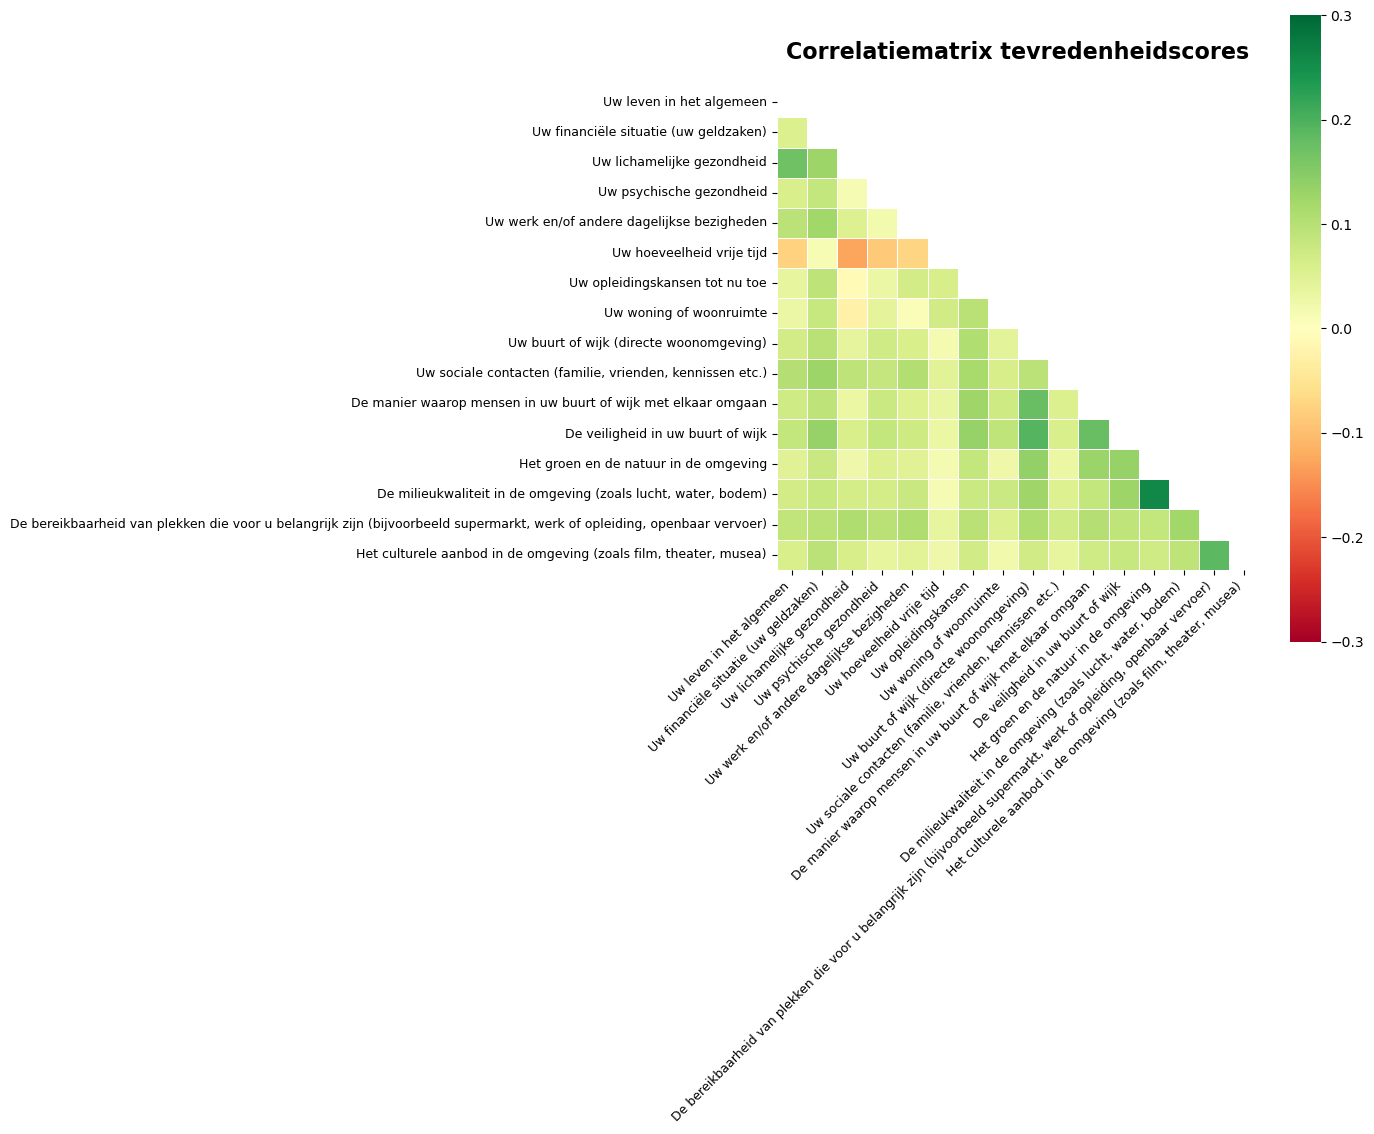

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(14, 12))

# Mask upper triangle for cleaner look
mask = np.triu(np.ones_like(corr_matrix_toekomst, dtype=bool))

sns.heatmap(
    corr_matrix_toekomst,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    vmin=-0.3, vmax=0.3,
    square=True,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    ax=ax
)

ax.set_title("Correlatiematrix tevredenheidscores", fontsize=16, fontweight="bold", pad=20)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig("correlatiematrix_tevredenheid.png", dpi=150, bbox_inches="tight")
plt.show()

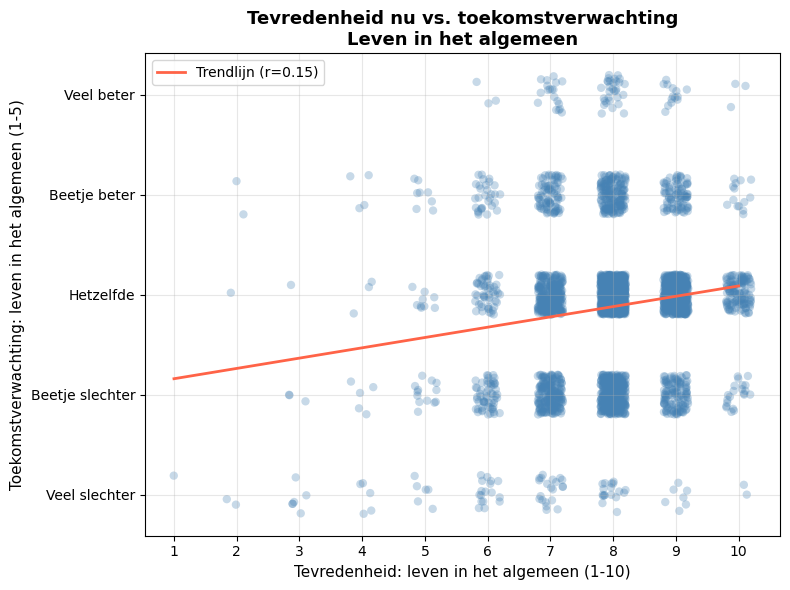

In [23]:
import matplotlib.pyplot as plt

x = tevreden_df["Uw leven in het algemeen"]
y = toekomst_df["Uw leven in het algemeen"]

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(x, y, alpha=0.3, edgecolors="none", color="steelblue")

# Add jitter to avoid overplotting on discrete scales
import numpy as np
x_jitter = x + np.random.uniform(-0.2, 0.2, size=len(x))
y_jitter = y + np.random.uniform(-0.2, 0.2, size=len(y))

ax.clear()
ax.scatter(x_jitter, y_jitter, alpha=0.3, edgecolors="none", color="steelblue")

# Trend line
mask = x.notna() & y.notna()
m, b = np.polyfit(x[mask], y[mask], 1)
x_line = np.linspace(x.min(), x.max(), 100)
ax.plot(x_line, m * x_line + b, color="tomato", linewidth=2, label=f"Trendlijn (r={x[mask].corr(y[mask]):.2f})")

ax.set_xlabel("Tevredenheid: leven in het algemeen (1-10)", fontsize=11)
ax.set_ylabel("Toekomstverwachting: leven in het algemeen (1-5)", fontsize=11)
ax.set_title("Tevredenheid nu vs. toekomstverwachting\nLeven in het algemeen", fontsize=13, fontweight="bold")
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 6))
ax.yaxis.set_ticklabels(["Veel slechter", "Beetje slechter", "Hetzelfde", "Beetje beter", "Veel beter"])
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("scatter_leven_tevredenheid_toekomst.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
# Subjects that appear in both tevredenheid and toekomst
subjects = [col for col in tevreden_df.columns if col in toekomst_df.columns]

for subject in subjects:
    tev = tevreden_df[subject]
    toe = toekomst_df[subject]

    conditions = [
    (tev >= 7) & (toe >= 3),   # tevreden & stabiel of beter
    (tev >= 7) & (toe < 3),    # tevreden & pessimistisch
    (tev < 7)  & (toe >= 3),   # ontevreden & stabiel of beter/optimistisch
    (tev < 7)  & (toe < 3),    # ontevreden & pessimistisch
]
    labels = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]

    col_name = f"situatie_{subject.lower().replace(' ', '_').replace('/', '_')[:40]}"
    df[col_name] = np.select(conditions, labels, default=np.nan)

# Check result
situatie_cols = [col for col in df.columns if col.startswith("situatie_")]


In [25]:
print([col for col in df.columns if 'weeg' in col])

['weegfactor']


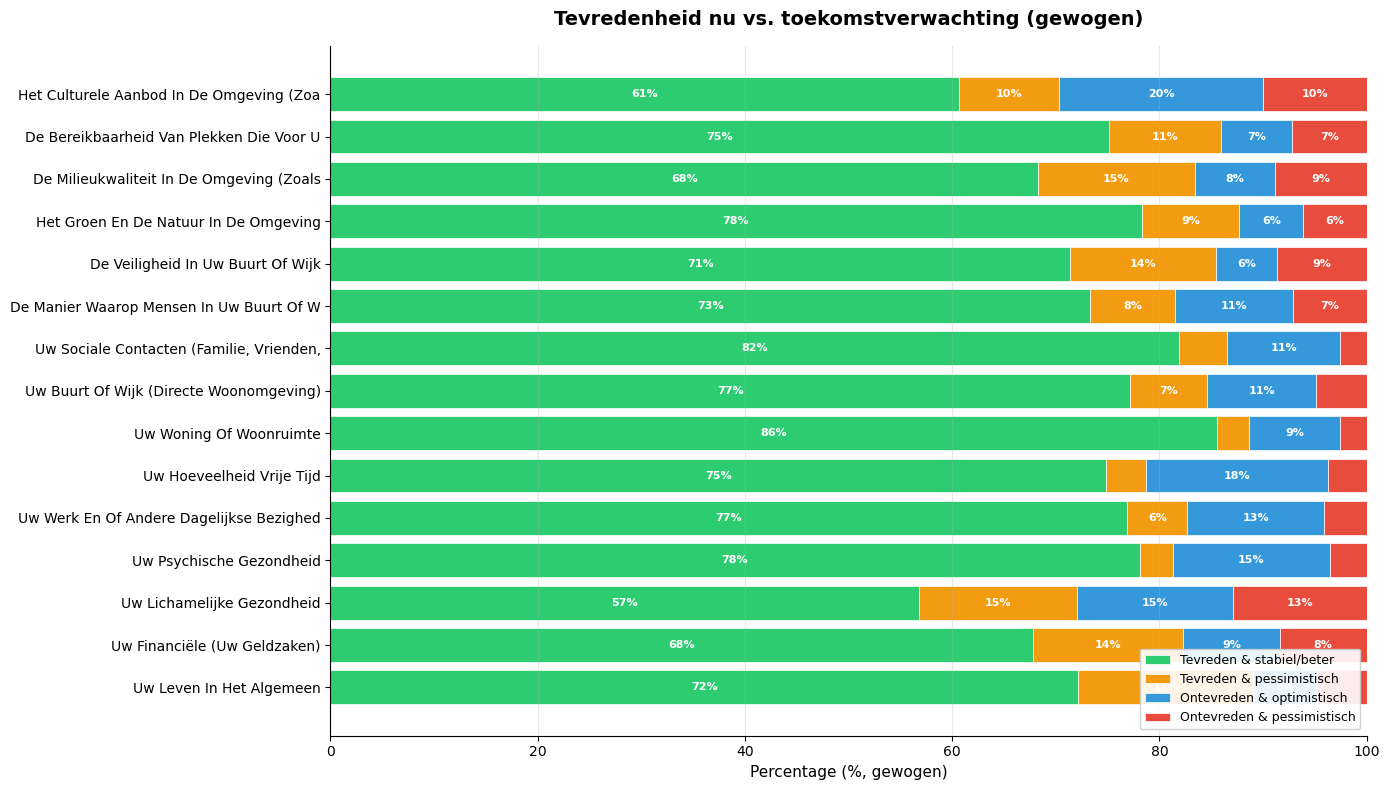

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

weight_col = 'weegfactor'

# Compute weighted proportions per subject
records = []
for col in situatie_cols:
    sub = df[[col, weight_col]].dropna(subset=[col, weight_col])
    weighted_counts = sub.groupby(col)[weight_col].sum()
    weighted_pct = weighted_counts / weighted_counts.sum() * 100
    weighted_pct.name = col.replace("situatie_", "").replace("_", " ").title()
    records.append(weighted_pct)

prop_df = pd.DataFrame(records).fillna(0)


cat_order = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]

# Consistent column order
prop_df = prop_df[[c for c in cat_order if c in prop_df.columns]]
prop_df = prop_df.div(prop_df.sum(axis=1), axis=0) * 100

colors = {
    "tevreden_en_stabiel":         "#2ecc71",
    "tevreden_en_pessimistisch":   "#f39c12",
    "ontevreden_en_optimistisch":  "#3498db",
    "ontevreden_en_pessimistisch": "#e74c3c",
}
labels_map = {
    "tevreden_en_stabiel":         "Tevreden & stabiel/beter",
    "tevreden_en_pessimistisch":   "Tevreden & pessimistisch",
    "ontevreden_en_optimistisch":  "Ontevreden & optimistisch",
    "ontevreden_en_pessimistisch": "Ontevreden & pessimistisch",
}

fig, ax = plt.subplots(figsize=(14, 8))

left = np.zeros(len(prop_df))
for cat in cat_order:
    if cat not in prop_df.columns:
        continue
    ax.barh(
        prop_df.index,
        prop_df[cat],
        left=left,
        color=colors[cat],
        label=labels_map[cat],
        edgecolor="white",
        linewidth=0.5,
    )
    for i, (val, l) in enumerate(zip(prop_df[cat], left)):
        if val > 5:
            ax.text(l + val / 2, i, f"{val:.0f}%", ha="center", va="center",
                    fontsize=8, color="white", fontweight="bold")
    left += prop_df[cat].values

ax.set_xlim(0, 100)
ax.set_xlabel("Percentage (%, gewogen)", fontsize=11)
ax.set_title("Tevredenheid nu vs. toekomstverwachting (gewogen)", 
             fontsize=14, fontweight="bold", pad=15)
ax.legend(loc="lower right", fontsize=9, framealpha=0.9)
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("stacked_bar_situatie_gewogen.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# Keep only the first occurrence of any duplicate column name
df = df.loc[:, ~df.columns.duplicated()]

print(f"Shape na dedupe: {df.shape}")
print("Resterende duplicaten:", df.columns.duplicated().sum())

Shape na dedupe: (3737, 284)
Resterende duplicaten: 0


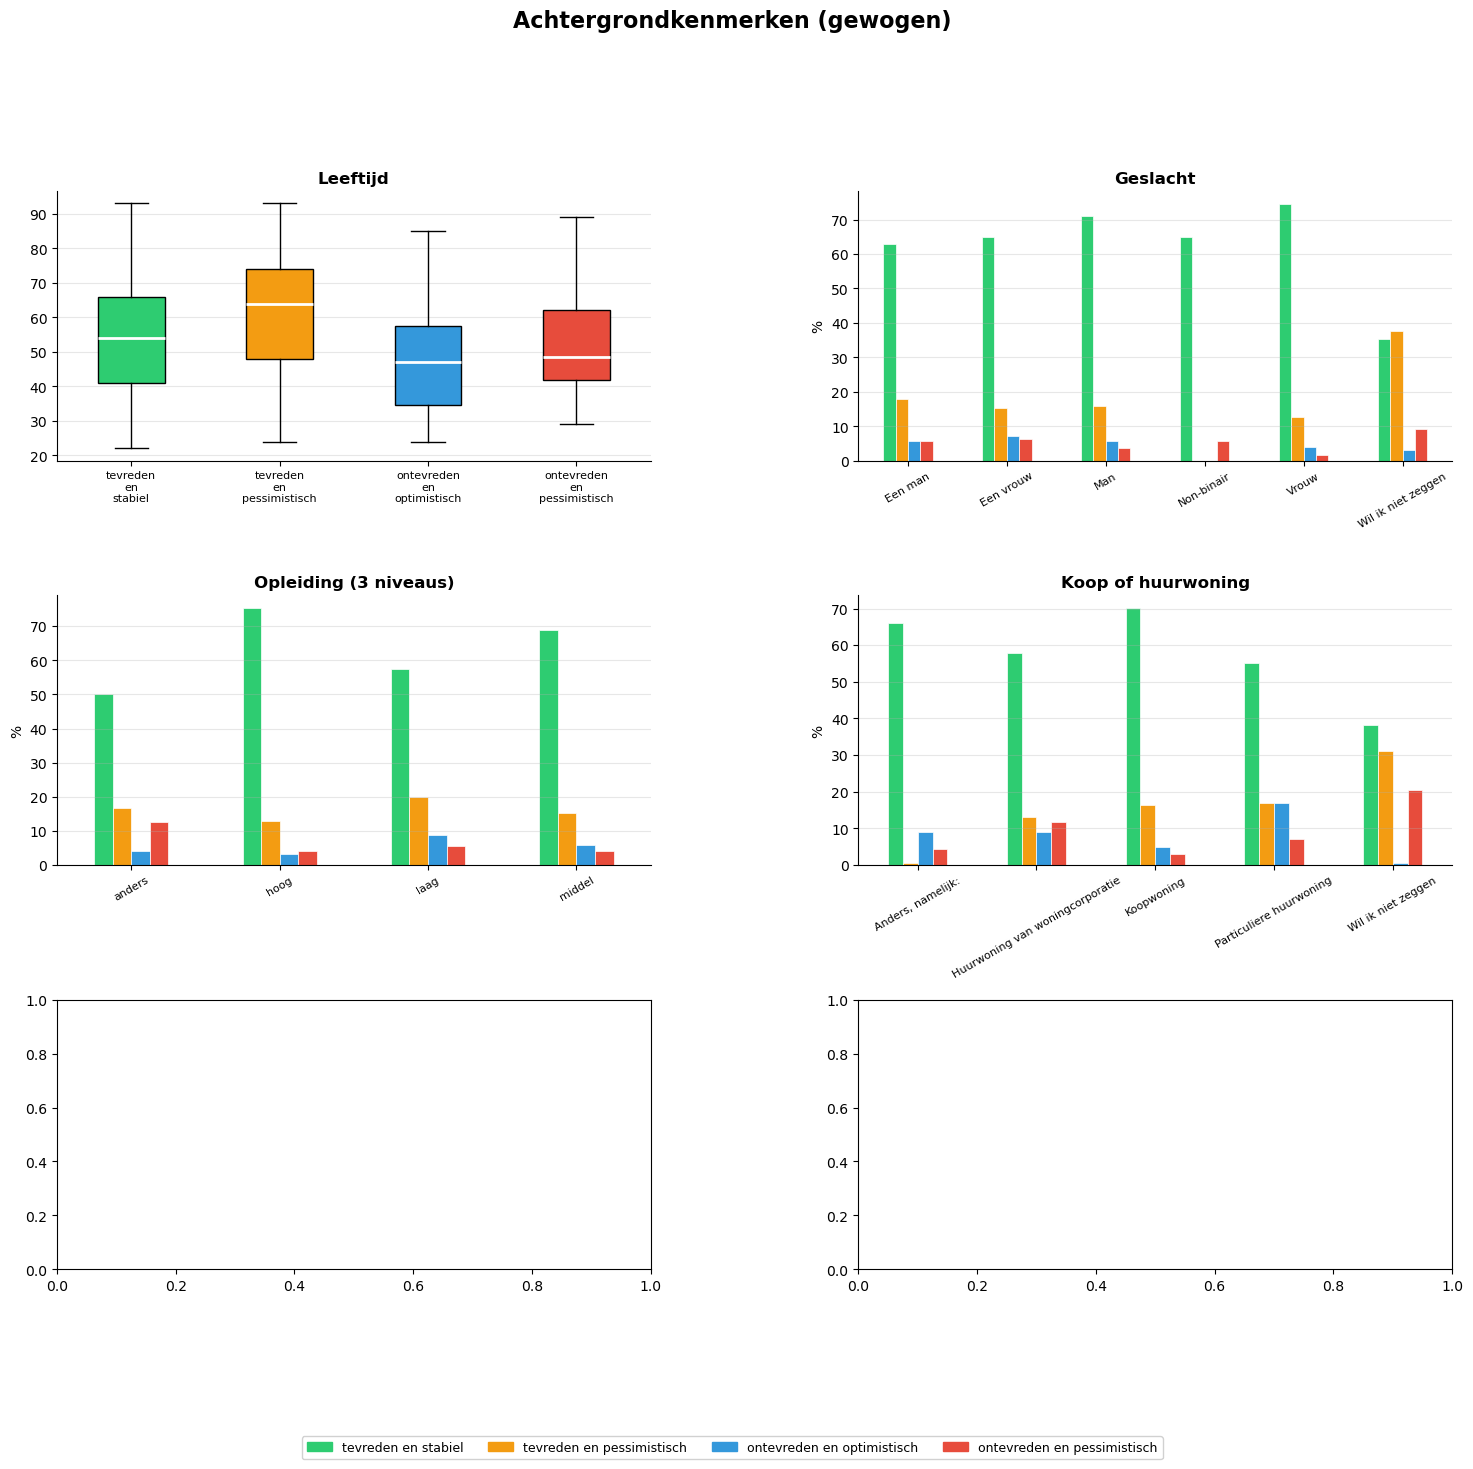

In [28]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

situatie_leven = "situatie_uw_leven_in_het_algemeen"
weight_col = "weegfactor"
background_vars = [v for v in ["Leeftijd", "Geslacht", "Opleiding (3 niveaus)",
                                "Inkomen in 3 categorieÃ«n", "Koop of huurwoning", "stadplatteland"]
                    if v in df.columns]
cat_vars = [v for v in background_vars if v != "Leeftijd"]
desc_df = df[[situatie_leven] + background_vars + [weight_col]].dropna(subset=[situatie_leven])

cat_order = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]
colors_groep = {"tevreden_en_stabiel": "#2ecc71", "tevreden_en_pessimistisch": "#f39c12",
                "ontevreden_en_optimistisch": "#3498db", "ontevreden_en_pessimistisch": "#e74c3c"}

def wq(v, w, q):  # weighted quantile
    v, w = np.asarray(v, float), np.asarray(w, float)
    o = np.argsort(v); v, w = v[o], w[o]
    cw = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, cw, v)

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Achtergrondkenmerken (gewogen)", fontsize=16, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.35)
axes = [fig.add_subplot(gs[i, j]) for i in range(3) for j in range(2)]

# Leeftijd: gewogen boxplot
ax = axes[0]
stats = []
for g in cat_order:
    sub = desc_df[desc_df[situatie_leven] == g][["Leeftijd", weight_col]].dropna()
    v, w = sub["Leeftijd"].values, sub[weight_col].values
    q1, med, q3 = wq(v, w, 0.25), wq(v, w, 0.5), wq(v, w, 0.75)
    stats.append({"med": med, "q1": q1, "q3": q3, "whislo": v.min(), "whishi": v.max(), "fliers": []})
bp = ax.bxp(stats, patch_artist=True, medianprops=dict(color="white", linewidth=2))
for patch, g in zip(bp["boxes"], cat_order):
    patch.set_facecolor(colors_groep[g])
ax.set_xticklabels([g.replace("_", "\n") for g in cat_order], fontsize=8)
ax.set_title("Leeftijd", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

# Categorische vars: gewogen grouped bar charts
for idx, var in enumerate(cat_vars):
    ax = axes[idx + 1]
    sub = desc_df[[situatie_leven, var, weight_col]].dropna()
    ct = sub.groupby([situatie_leven, var])[weight_col].sum().unstack(fill_value=0)
    ct = (ct / ct.sum() * 100).reindex(cat_order).dropna(how="all")
    ct.T.plot(kind="bar", ax=ax, color=[colors_groep[g] for g in ct.index],
              edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(var, fontweight="bold")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors_groep[g]) for g in cat_order]
fig.legend(handles, [g.replace("_", " ") for g in cat_order], loc="lower center", ncol=4,
           fontsize=9, bbox_to_anchor=(0.5, -0.03), framealpha=0.9)

plt.savefig("descriptives_situatie_leven_gewogen.png", dpi=150, bbox_inches="tight")
plt.show()

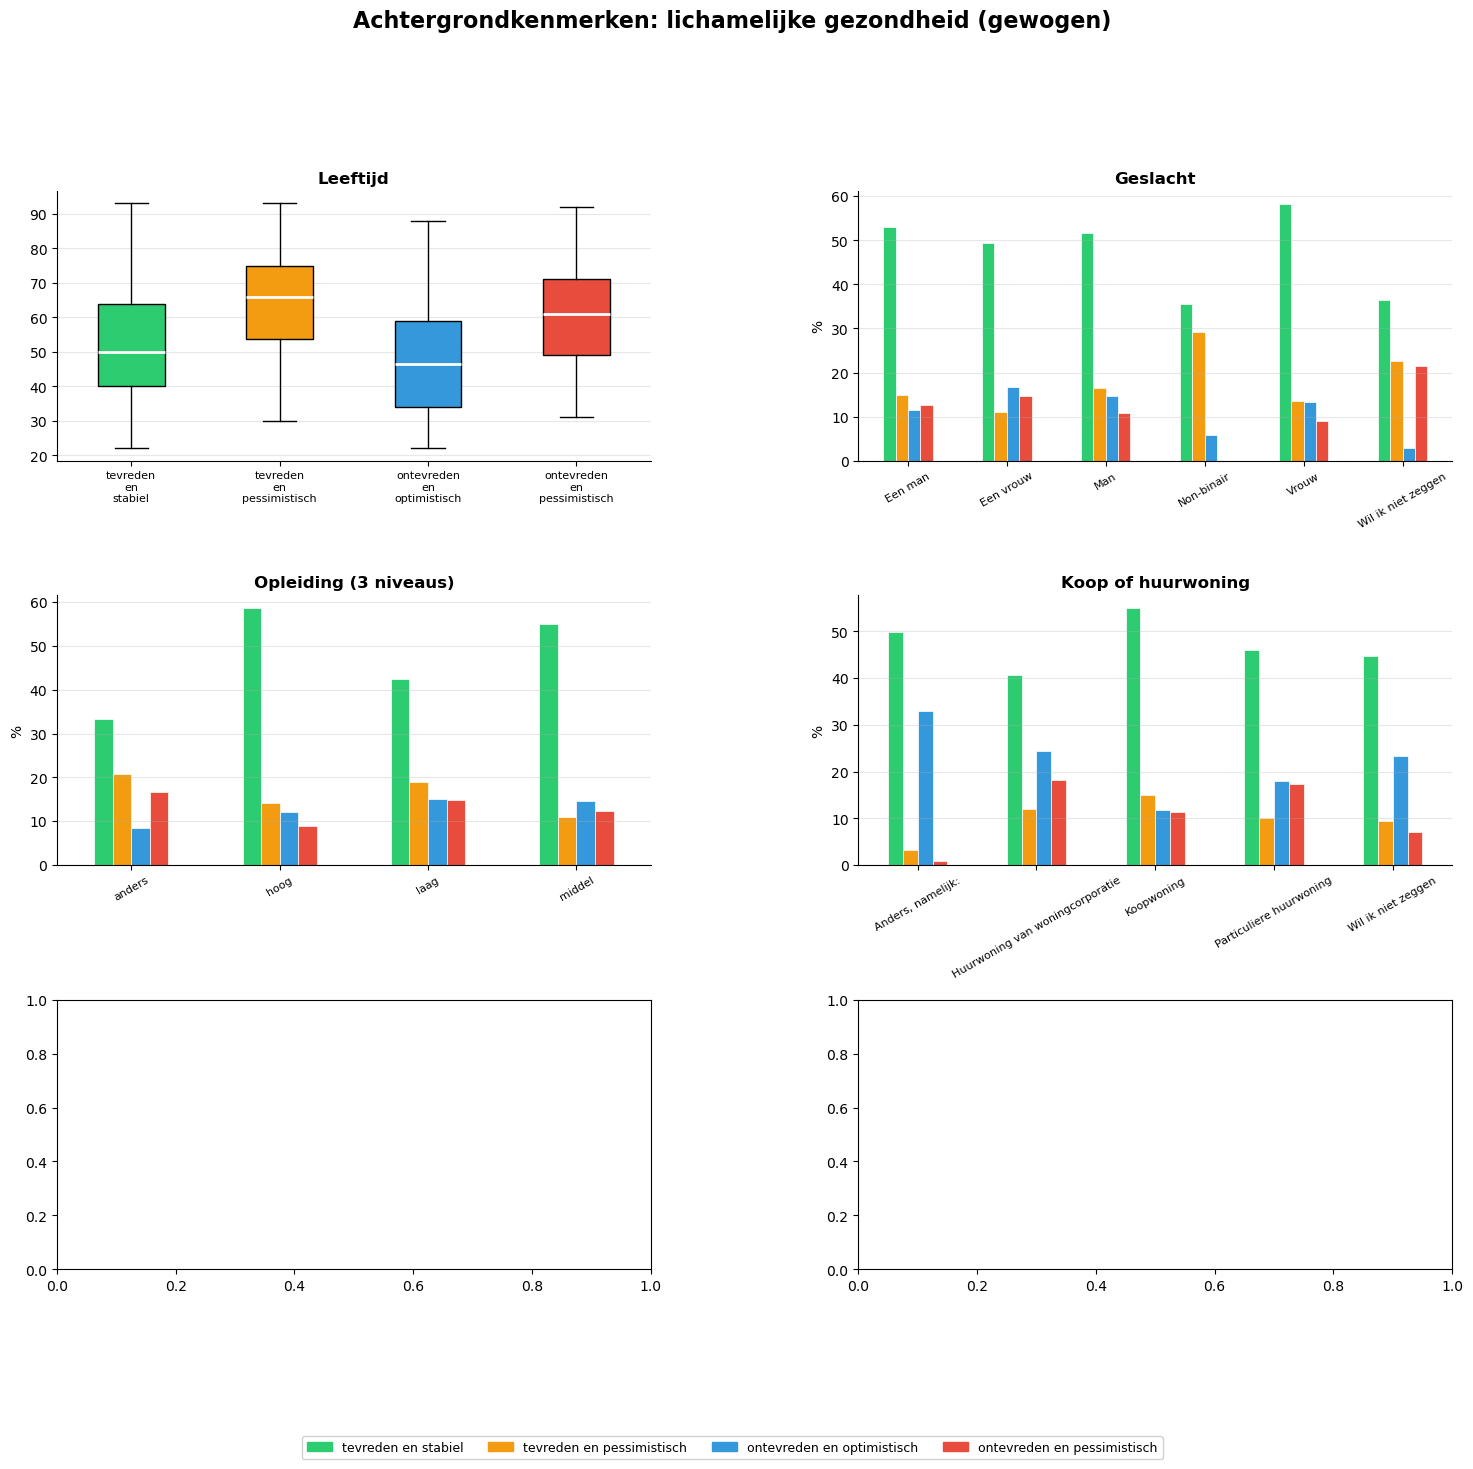

In [29]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

situatie_leven = "situatie_uw_lichamelijke_gezondheid"
weight_col = "weegfactor"
background_vars = [v for v in ["Leeftijd", "Geslacht", "Opleiding (3 niveaus)",
                                "Inkomen in 3 categorieÃ«n", "Koop of huurwoning", "stadplatteland"]
                    if v in df.columns]
cat_vars = [v for v in background_vars if v != "Leeftijd"]
desc_df = df[[situatie_leven] + background_vars + [weight_col]].dropna(subset=[situatie_leven])

cat_order = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]
colors_groep = {"tevreden_en_stabiel": "#2ecc71", "tevreden_en_pessimistisch": "#f39c12",
                "ontevreden_en_optimistisch": "#3498db", "ontevreden_en_pessimistisch": "#e74c3c"}

def wq(v, w, q):  # weighted quantile
    v, w = np.asarray(v, float), np.asarray(w, float)
    o = np.argsort(v); v, w = v[o], w[o]
    cw = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, cw, v)

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Achtergrondkenmerken: lichamelijke gezondheid (gewogen)", fontsize=16, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.35)
axes = [fig.add_subplot(gs[i, j]) for i in range(3) for j in range(2)]

# Leeftijd: gewogen boxplot
ax = axes[0]
stats = []
for g in cat_order:
    sub = desc_df[desc_df[situatie_leven] == g][["Leeftijd", weight_col]].dropna()
    v, w = sub["Leeftijd"].values, sub[weight_col].values
    q1, med, q3 = wq(v, w, 0.25), wq(v, w, 0.5), wq(v, w, 0.75)
    stats.append({"med": med, "q1": q1, "q3": q3, "whislo": v.min(), "whishi": v.max(), "fliers": []})
bp = ax.bxp(stats, patch_artist=True, medianprops=dict(color="white", linewidth=2))
for patch, g in zip(bp["boxes"], cat_order):
    patch.set_facecolor(colors_groep[g])
ax.set_xticklabels([g.replace("_", "\n") for g in cat_order], fontsize=8)
ax.set_title("Leeftijd", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

# Categorische vars: gewogen grouped bar charts
for idx, var in enumerate(cat_vars):
    ax = axes[idx + 1]
    sub = desc_df[[situatie_leven, var, weight_col]].dropna()
    ct = sub.groupby([situatie_leven, var])[weight_col].sum().unstack(fill_value=0)
    ct = (ct / ct.sum() * 100).reindex(cat_order).dropna(how="all")
    ct.T.plot(kind="bar", ax=ax, color=[colors_groep[g] for g in ct.index],
              edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(var, fontweight="bold")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors_groep[g]) for g in cat_order]
fig.legend(handles, [g.replace("_", " ") for g in cat_order], loc="lower center", ncol=4,
           fontsize=9, bbox_to_anchor=(0.5, -0.03), framealpha=0.9)

plt.savefig("descriptives_situatie_gezondheid_gewogen.png", dpi=150, bbox_inches="tight")
plt.show()

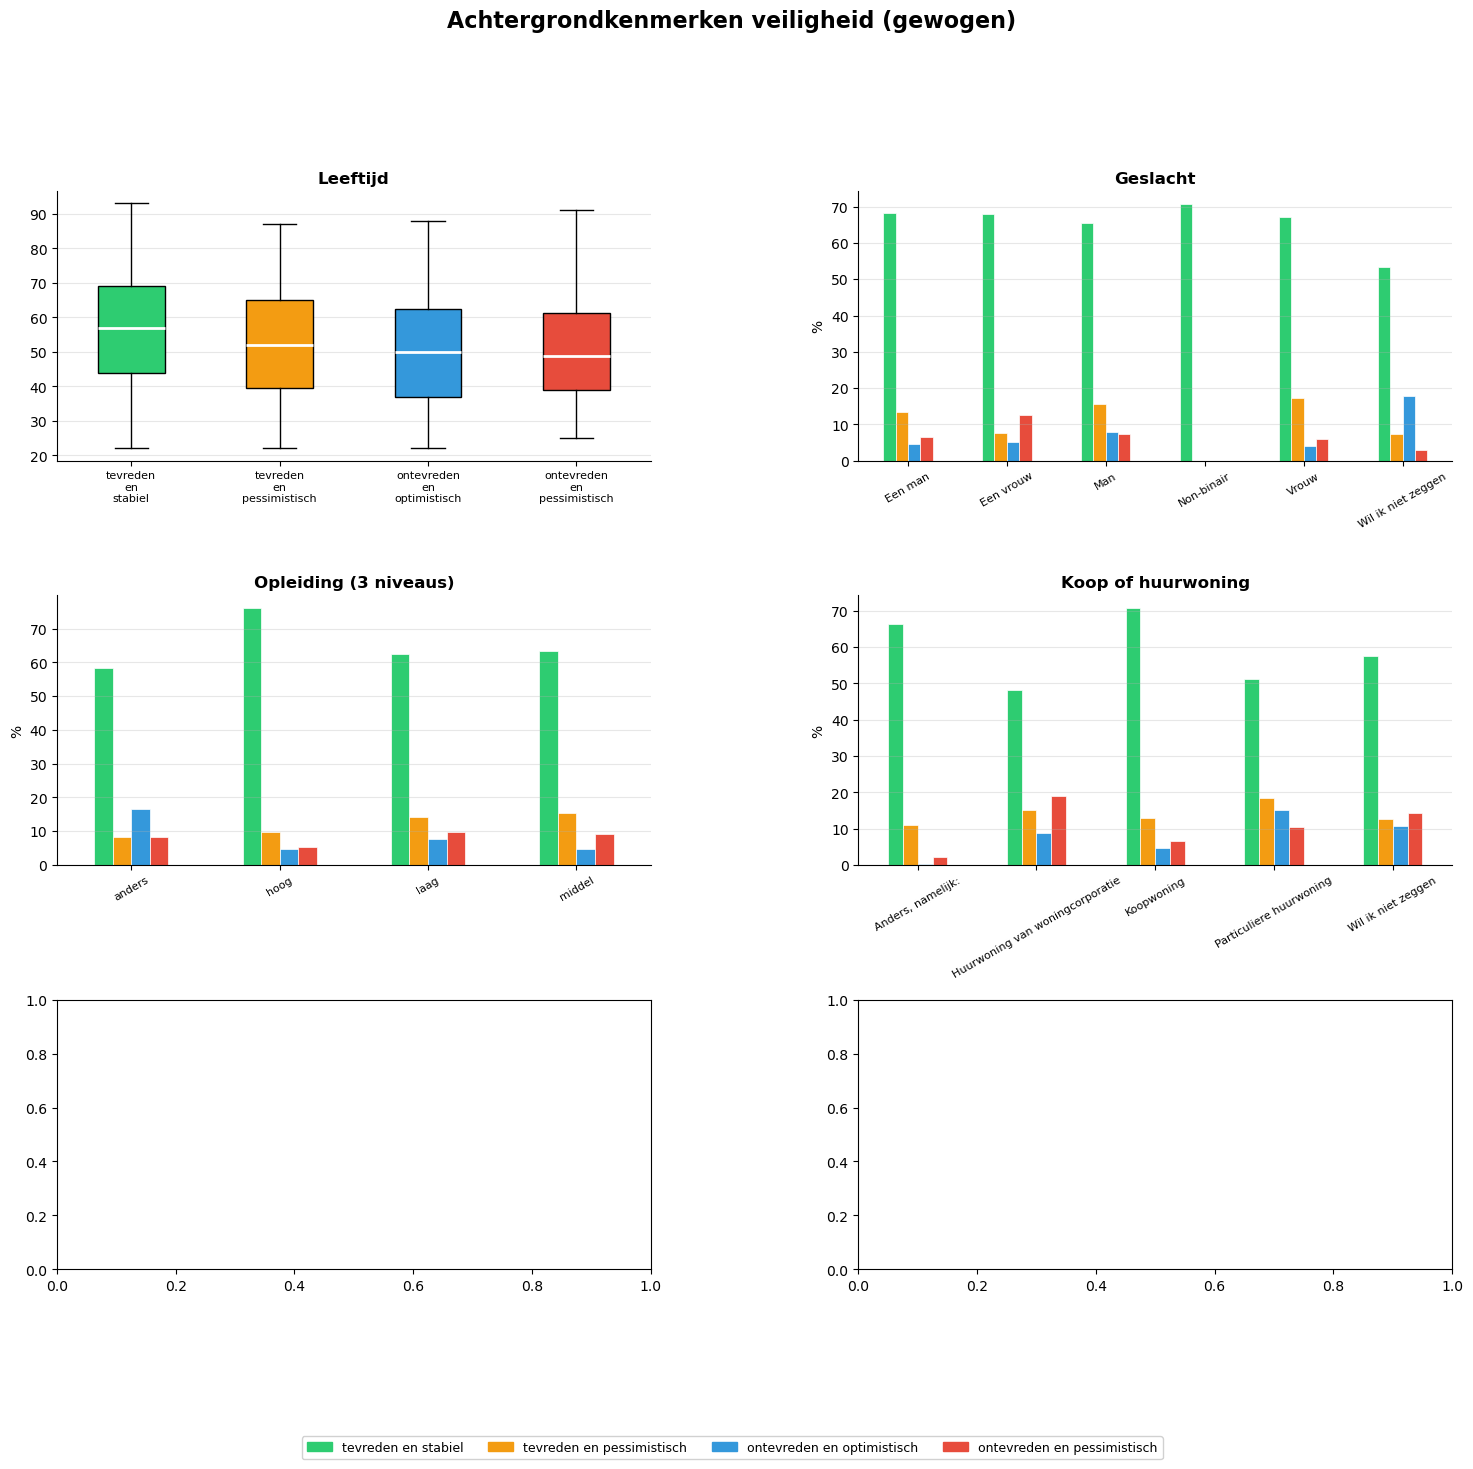

In [30]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

situatie_leven = "situatie_de_veiligheid_in_uw_buurt_of_wijk"
weight_col = "weegfactor"
background_vars = [v for v in ["Leeftijd", "Geslacht", "Opleiding (3 niveaus)",
                                "Inkomen in 3 categorieën", "Koop of huurwoning", "stadplatteland"]
                    if v in df.columns]
cat_vars = [v for v in background_vars if v != "Leeftijd"]
desc_df = df[[situatie_leven] + background_vars + [weight_col]].dropna(subset=[situatie_leven])

cat_order = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]
colors_groep = {"tevreden_en_stabiel": "#2ecc71", "tevreden_en_pessimistisch": "#f39c12",
                "ontevreden_en_optimistisch": "#3498db", "ontevreden_en_pessimistisch": "#e74c3c"}

def wq(v, w, q):
    v, w = np.asarray(v, float), np.asarray(w, float)
    o = np.argsort(v); v, w = v[o], w[o]
    cw = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, cw, v)

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Achtergrondkenmerken veiligheid (gewogen)", fontsize=16, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.35)
axes = [fig.add_subplot(gs[i, j]) for i in range(3) for j in range(2)]

ax = axes[0]
stats = []
for g in cat_order:
    sub = desc_df[desc_df[situatie_leven] == g][["Leeftijd", weight_col]].dropna()
    v, w = sub["Leeftijd"].values, sub[weight_col].values
    q1, med, q3 = wq(v, w, 0.25), wq(v, w, 0.5), wq(v, w, 0.75)
    stats.append({"med": med, "q1": q1, "q3": q3, "whislo": v.min(), "whishi": v.max(), "fliers": []})
bp = ax.bxp(stats, patch_artist=True, medianprops=dict(color="white", linewidth=2))
for patch, g in zip(bp["boxes"], cat_order):
    patch.set_facecolor(colors_groep[g])
ax.set_xticklabels([g.replace("_", "\n") for g in cat_order], fontsize=8)
ax.set_title("Leeftijd", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

for idx, var in enumerate(cat_vars):
    ax = axes[idx + 1]
    sub = desc_df[[situatie_leven, var, weight_col]].dropna()
    ct = sub.groupby([situatie_leven, var])[weight_col].sum().unstack(fill_value=0)
    ct = (ct / ct.sum() * 100).reindex(cat_order).dropna(how="all")
    ct.T.plot(kind="bar", ax=ax, color=[colors_groep[g] for g in ct.index],
              edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(var, fontweight="bold")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors_groep[g]) for g in cat_order]
fig.legend(handles, [g.replace("_", " ") for g in cat_order], loc="lower center", ncol=4,
           fontsize=9, bbox_to_anchor=(0.5, -0.03), framealpha=0.9)

plt.savefig("descriptives_situatie_veiligheid_buurt_gewogen.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
print([c for c in df.columns if c.startswith("situatie_")])

['situatie_uw_leven_in_het_algemeen', 'situatie_uw_financiële_situatie_(uw_geldzaken)', 'situatie_uw_lichamelijke_gezondheid', 'situatie_uw_psychische_gezondheid', 'situatie_uw_werk_en_of_andere_dagelijkse_bezighed', 'situatie_uw_hoeveelheid_vrije_tijd', 'situatie_uw_woning_of_woonruimte', 'situatie_uw_buurt_of_wijk_(directe_woonomgeving)', 'situatie_uw_sociale_contacten_(familie,_vrienden,', 'situatie_de_manier_waarop_mensen_in_uw_buurt_of_w', 'situatie_de_veiligheid_in_uw_buurt_of_wijk', 'situatie_het_groen_en_de_natuur_in_de_omgeving', 'situatie_de_milieukwaliteit_in_de_omgeving_(zoals', 'situatie_de_bereikbaarheid_van_plekken_die_voor_u', 'situatie_het_culturele_aanbod_in_de_omgeving_(zoa']


In [32]:
import pandas as pd

invloed_cols = [c for c in df.columns if "hoeveel invloed" in c.lower()]

invloed_dummy_cols = []
for c in invloed_cols:
    subject = c.split(" - ")[-1].strip()
    dummy_name = f"{subject}_invloed"
    df[dummy_name] = df[c].astype(str).str.lower().str.contains("veel|beetje", na=False, regex=True).astype(int)
    df.loc[df[c].isna(), dummy_name] = pd.NA
    invloed_dummy_cols.append(dummy_name)

# â”€â”€ Check: does the dummy match expectations? â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
for c, d in zip(invloed_cols, invloed_dummy_cols):
    print(f"\n=== {c} -> {d} ===")
    print(pd.crosstab(df[c], df[d], dropna=False))


=== Hoeveel invloed denkt u dat u heeft op: - Uw leven in het algemeen -> Uw leven in het algemeen_invloed ===
Uw leven in het algemeen_invloed                    0.0   1.0  NaN
Hoeveel invloed denkt u dat u heeft op: - Uw le...                
Een beetje invloed                                    0  1561    0
Geen invloed                                        170     0    0
Veel invloed                                          0  1915    0
Weet ik niet                                         75     0    0
NaN                                                   0     0   16

=== Hoeveel invloed denkt u dat u heeft op: - Uw financiële situatie (uw geldzaken) -> Uw financiële situatie (uw geldzaken)_invloed ===
Uw financiële situatie (uw geldzaken)_invloed       0.0   1.0  NaN
Hoeveel invloed denkt u dat u heeft op: - Uw fi...                
Een beetje invloed                                    0  1794    0
Geen invloed                                        673     0    0
Veel invloed 

Doelvariabele: Uw leven in het algemeen
Predictor-subjects: ['Uw financiële situatie (uw geldzaken)', 'Uw lichamelijke gezondheid', 'Uw psychische gezondheid', 'Uw werk en/of andere dagelijkse bezigheden', 'Uw hoeveelheid vrije tijd', 'Uw woning of woonruimte', 'Uw buurt of wijk (directe woonomgeving)', 'Uw sociale contacten (familie, vrienden, kennissen etc.)', 'De manier waarop mensen in uw buurt of wijk met elkaar omgaan', 'De veiligheid in uw buurt of wijk', 'Het groen en de natuur in de omgeving', 'De milieukwaliteit in de omgeving (zoals lucht, water, bodem)', 'De bereikbaarheid van plekken die voor u belangrijk zijn (bijvoorbeeld supermarkt, werk of opleiding, openbaar vervoer)', 'Het culturele aanbod in de omgeving (zoals film, theater, musea)']

N vÃ³Ã³r imputatie (na dropna op target): 3728

Missende waarden per predictor (vÃ³Ã³r imputatie):
Uw financiële situatie (uw geldzaken)_nu                                                                                             13


C:\Users\mkooistra\AppData\Local\Temp\108\ipykernel_7848\3056261072.py:56: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


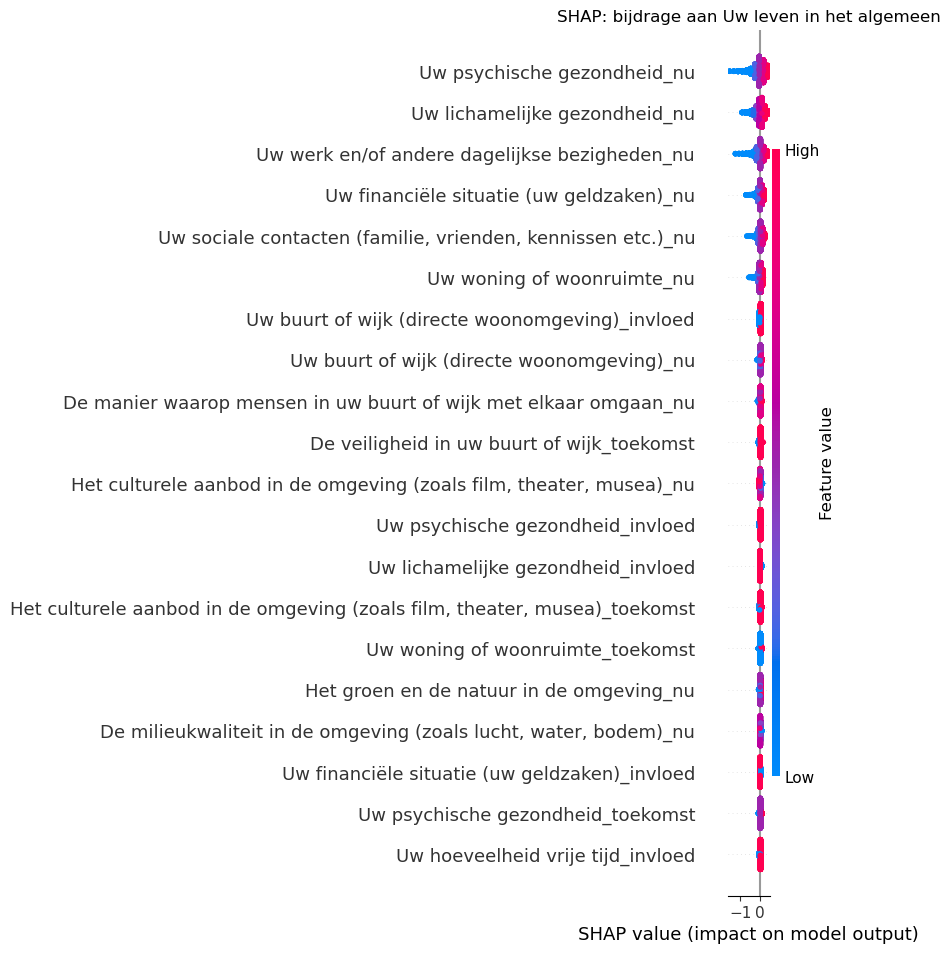


Gemiddelde |SHAP-waarde| per feature:
Uw psychische gezondheid_nu                                                                                                         0.220797
Uw lichamelijke gezondheid_nu                                                                                                       0.161961
Uw werk en/of andere dagelijkse bezigheden_nu                                                                                       0.145385
Uw financiële situatie (uw geldzaken)_nu                                                                                            0.097256
Uw sociale contacten (familie, vrienden, kennissen etc.)_nu                                                                         0.082420
Uw woning of woonruimte_nu                                                                                                          0.070570
Uw buurt of wijk (directe woonomgeving)_invloed                                                                    

In [33]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# â”€â”€ 1. Doelvariabele: tevredenheid nu, "leven in het algemeen" â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
target_subject = [c for c in tevreden_df.columns if "leven in het algemeen" in c.lower()]
assert len(target_subject) == 1, f"Verwachtte 1 match, kreeg: {target_subject}"
target_subject = target_subject[0]
print("Doelvariabele:", target_subject)

# â”€â”€ 2. Predictor-subjects: alle andere subjects (nu + toekomst), exclusief target â”€
predictor_subjects = [s for s in subjects if s != target_subject]
print("Predictor-subjects:", predictor_subjects)

# â”€â”€ 3. Regressiedataframe opbouwen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
reg_df = pd.DataFrame({"score": tevreden_df[target_subject], "Leeftijd": df["Leeftijd"]})
for s in predictor_subjects:
    reg_df[f"{s}_nu"] = tevreden_df[s]
    reg_df[f"{s}_toekomst"] = toekomst_df[s]
for d in invloed_dummy_cols:
    reg_df[d] = df[d]

# Alleen rijen droppen waar de DOELVARIABELE mist â€” X wordt zo dadelijk geÃ¯mputeerd
reg_df = reg_df.dropna(subset=["score"])
print(f"\nN vÃ³Ã³r imputatie (na dropna op target): {len(reg_df)}")

# â”€â”€ 3b. Mean-imputatie voor missende predictoren â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
predictor_cols = [c for c in reg_df.columns if c != "score"]
n_missing_per_col = reg_df[predictor_cols].isna().sum()
print("\nMissende waarden per predictor (vÃ³Ã³r imputatie):")
print(n_missing_per_col[n_missing_per_col > 0])

reg_df[predictor_cols] = reg_df[predictor_cols].astype(float)
reg_df[predictor_cols] = reg_df[predictor_cols].fillna(reg_df[predictor_cols].mean())

print(f"\nN na imputatie: {len(reg_df)}")

# â”€â”€ 4. OLS regressie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
X = reg_df.drop(columns="score")
y = reg_df["score"]

X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()
print(model.summary())

# â”€â”€ 5. SHAP decompositie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
lr = LinearRegression().fit(X, y)
explainer = shap.LinearExplainer(lr, X)
shap_values = explainer(X)

shap.summary_plot(shap_values, X, show=False)
plt.title(f"SHAP: bijdrage aan {target_subject}")
plt.tight_layout()
plt.savefig("shap_summary_leven_algemeen.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nGemiddelde |SHAP-waarde| per feature:")
print(pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns).sort_values(ascending=False))

Doelvariabele: Uw leven in het algemeen (toekomst)
Predictor-subjects: ['Uw financiële situatie (uw geldzaken)', 'Uw lichamelijke gezondheid', 'Uw psychische gezondheid', 'Uw werk en/of andere dagelijkse bezigheden', 'Uw hoeveelheid vrije tijd', 'Uw woning of woonruimte', 'Uw buurt of wijk (directe woonomgeving)', 'Uw sociale contacten (familie, vrienden, kennissen etc.)', 'De manier waarop mensen in uw buurt of wijk met elkaar omgaan', 'De veiligheid in uw buurt of wijk', 'Het groen en de natuur in de omgeving', 'De milieukwaliteit in de omgeving (zoals lucht, water, bodem)', 'De bereikbaarheid van plekken die voor u belangrijk zijn (bijvoorbeeld supermarkt, werk of opleiding, openbaar vervoer)', 'Het culturele aanbod in de omgeving (zoals film, theater, musea)']

N = 2532
                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       0.460
Model:                            OLS   Adj. R-squared:  

c:\Users\mkooistra\AppData\Local\anaconda3\Lib\site-packages\shap\plots\_beeswarm.py:950: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  pl.tight_layout()
C:\Users\mkooistra\AppData\Local\Temp\108\ipykernel_7848\3191837130.py:41: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


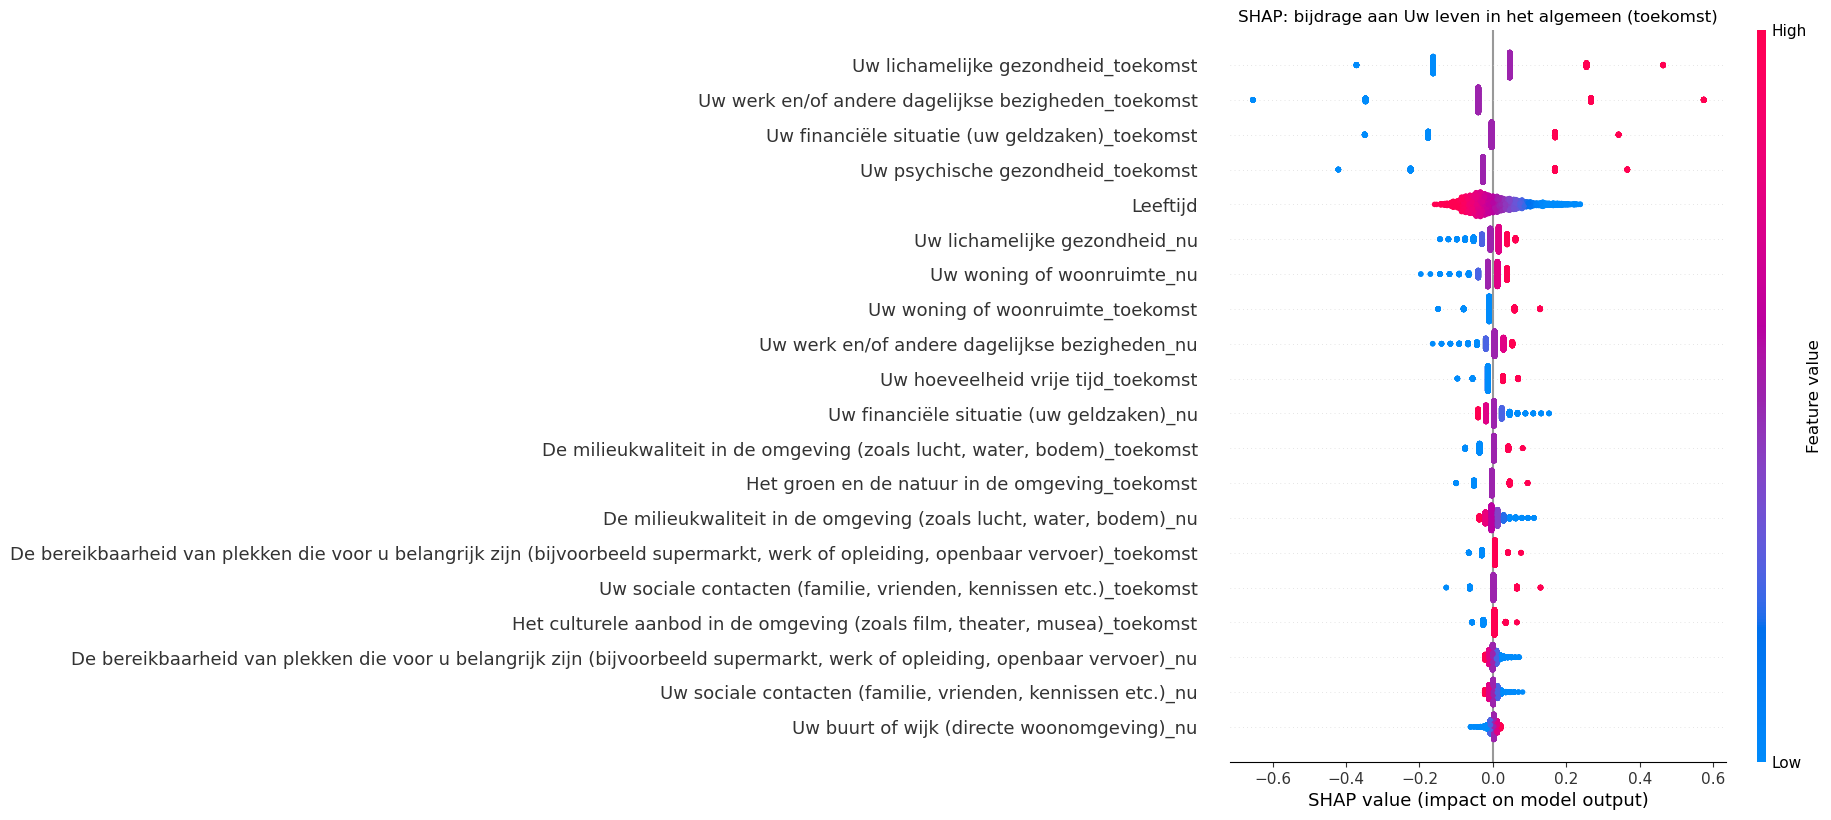


Gemiddelde |SHAP-waarde| per feature:
Uw lichamelijke gezondheid_toekomst                                                                                                 0.116821
Uw werk en/of andere dagelijkse bezigheden_toekomst                                                                                 0.112443
Uw financiële situatie (uw geldzaken)_toekomst                                                                                      0.067951
Uw psychische gezondheid_toekomst                                                                                                   0.062913
Leeftijd                                                                                                                            0.055933
Uw lichamelijke gezondheid_nu                                                                                                       0.025486
Uw woning of woonruimte_nu                                                                                         

In [34]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# â”€â”€ 1. Doelvariabele: toekomstverwachting, "leven in het algemeen" â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
target_subject = [c for c in toekomst_df.columns if "leven in het algemeen" in c.lower()]
assert len(target_subject) == 1, f"Verwachtte 1 match, kreeg: {target_subject}"
target_subject = target_subject[0]
print("Doelvariabele:", target_subject, "(toekomst)")

# â”€â”€ 2. Predictor-subjects: alle andere subjects (nu + toekomst), exclusief target â”€
predictor_subjects = [s for s in subjects if s != target_subject]
print("Predictor-subjects:", predictor_subjects)

# â”€â”€ 3. Regressiedataframe opbouwen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
reg_df = pd.DataFrame({"score": toekomst_df[target_subject], "Leeftijd": df["Leeftijd"]})
for s in predictor_subjects:
    reg_df[f"{s}_nu"] = tevreden_df[s]
    reg_df[f"{s}_toekomst"] = toekomst_df[s]
reg_df = reg_df.dropna()
print(f"\nN = {len(reg_df)}")

# â”€â”€ 4. OLS regressie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
X = reg_df.drop(columns="score").astype(float)
y = reg_df["score"]

X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()
print(model.summary())

# â”€â”€ 5. SHAP decompositie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
lr = LinearRegression().fit(X, y)
explainer = shap.LinearExplainer(lr, X)
shap_values = explainer(X)

shap.summary_plot(shap_values, X, show=False)
plt.title(f"SHAP: bijdrage aan {target_subject} (toekomst)")
plt.tight_layout()
plt.savefig("shap_summary_leven_algemeen_toekomst.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nGemiddelde |SHAP-waarde| per feature:")
print(pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns).sort_values(ascending=False))

In [35]:
import pandas as pd

# â”€â”€ 1. Basic overview â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print(f"Shape: {df.shape}")
print(f"\nAantal kolommen: {len(df.columns)}")

# â”€â”€ 2. Group columns by likely type/topic â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
dtype_counts = df.dtypes.value_counts()
print("\n=== Dtypes ===")
print(dtype_counts)

# â”€â”€ 3. Split into rough categories based on naming patterns â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
situatie_cols_here = [c for c in df.columns if c.startswith("situatie_")]
achtergrond_cols = ["Leeftijd", "Geslacht", "opleiding 3 niveaus", "Inkomen in 3 categorieÃ«n",
                     "Koop of Huurwoning", "stadplatteland", "gemeente", "dorpstype",
                     "Krimpgemeente", "regioprovincie"]
achtergrond_cols = [c for c in achtergrond_cols if c in df.columns]

tevredenheid_cols = [c for c in df.columns if "hoe tevreden u bent met" in c.lower()]
toekomst_cols = [c for c in df.columns if "komende 5 jaar" in c.lower()]
invloed_cols = [c for c in df.columns if "hoeveel invloed" in c.lower()]
hulp_netwerk_cols = [c for c in df.columns if "zou kunnen helpen met" in c.lower() or "terechtkunt" in c.lower()]
weet_waar_hulp_cols = [c for c in df.columns if "welke organisaties ik terecht kan" in c.lower()]
situaties_van_toepassing_cols = [c for c in df.columns if "situaties zijn op u van toepassing" in c.lower() or "situaties is op u van toepassing" in c.lower()]
stellingen_cols = [c for c in df.columns if "in hoeverre u het eens bent" in c.lower()]
open_vragen_cols = [c for c in df.columns if "open answers" in c.lower() or "toelichting" in c.lower() or "opmerkingen" in c.lower()]

print(f"\n=== CategorieÃ«n ===")
print(f"Achtergrondkenmerken: {len(achtergrond_cols)}")
print(f"Tevredenheid (nu): {len(tevredenheid_cols)}")
print(f"Toekomstverwachting: {len(toekomst_cols)}")
print(f"Ervaren invloed: {len(invloed_cols)}")
print(f"Sociaal netwerk / hulp: {len(hulp_netwerk_cols)}")
print(f"Weet waar hulp te vinden: {len(weet_waar_hulp_cols)}")
print(f"Situaties van toepassing (bestaanszekerheid): {len(situaties_van_toepassing_cols)}")
print(f"Stellingen (kansengelijkheid): {len(stellingen_cols)}")
print(f"Open vragen: {len(open_vragen_cols)}")
print(f"Al aangemaakte situatie_ kolommen: {len(situatie_cols_here)}")

geclassificeerd = (len(achtergrond_cols) + len(tevredenheid_cols) + len(toekomst_cols) +
                    len(invloed_cols) + len(hulp_netwerk_cols) + len(weet_waar_hulp_cols) +
                    len(situaties_van_toepassing_cols) + len(stellingen_cols) + len(open_vragen_cols) +
                    len(situatie_cols_here))
print(f"\nNog niet geclassificeerd: {len(df.columns) - geclassificeerd}")

# â”€â”€ 4. Missingness per categorie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print("\n=== % missing per categorie (gemiddeld) ===")
for naam, cols in [("Achtergrond", achtergrond_cols), ("Tevredenheid", tevredenheid_cols),
                    ("Toekomst", toekomst_cols), ("Invloed", invloed_cols),
                    ("Situaties bestaanszekerheid", situaties_van_toepassing_cols),
                    ("Stellingen", stellingen_cols)]:
    if cols:
        print(f"{naam}: {df[cols].isna().mean().mean()*100:.1f}%")

Shape: (3737, 293)

Aantal kolommen: 293

=== Dtypes ===
float64    158
object     135
Name: count, dtype: int64

=== CategorieÃ«n ===
Achtergrondkenmerken: 3
Tevredenheid (nu): 16
Toekomstverwachting: 16
Ervaren invloed: 9
Sociaal netwerk / hulp: 14
Weet waar hulp te vinden: 9
Situaties van toepassing (bestaanszekerheid): 23
Stellingen (kansengelijkheid): 4
Open vragen: 0
Al aangemaakte situatie_ kolommen: 15

Nog niet geclassificeerd: 184

=== % missing per categorie (gemiddeld) ===
Achtergrond: 0.0%
Tevredenheid: 2.5%
Toekomst: 0.3%
Invloed: 0.4%
Situaties bestaanszekerheid: 0.5%
Stellingen: 0.5%


In [36]:
import pandas as pd

hulp_netwerk_cols = [c for c in df.columns if "zou kunnen helpen met" in c.lower() or "terechtkunt" in c.lower()]
weet_waar_hulp_cols = [c for c in df.columns if "welke organisaties ik terecht kan" in c.lower()]
situaties_van_toepassing_cols = [c for c in df.columns if "situaties zijn op u van toepassing" in c.lower() or "situaties is op u van toepassing" in c.lower()]

for naam, cols in [("Sociaal netwerk / hulp", hulp_netwerk_cols),
                    ("Weet waar hulp te vinden", weet_waar_hulp_cols),
                    ("Situaties van toepassing (bestaanszekerheid)", situaties_van_toepassing_cols)]:
    print(f"\n{'='*80}\n{naam} ({len(cols)} kolommen)\n{'='*80}")
    for c in cols:
        print(f"\n--- {c} ---")
        print(df[c].value_counts(dropna=False).head(10))


Sociaal netwerk / hulp (14 kolommen)

--- Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Uw huishouden ---
Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Uw huishouden
Ja              2814
Nee              624
Weet ik niet     282
NaN               17
Name: count, dtype: int64

--- Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Uw boodschappen ---
Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Uw boodschappen
Ja              3124
Nee              406
Weet ik niet     190
NaN               17
Name: count, dtype: int64

--- Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Vervoer (bijvoorbeeld u met de auto ergens naartoe brengen) ---
Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen hel

In [37]:
weight_col = "weegfactor"

hulp_netwerk_cols = [c for c in df.columns if "zou kunnen helpen met" in c.lower() or "terechtkunt" in c.lower()]
weet_waar_hulp_cols = [c for c in df.columns if "welke organisaties ik terecht kan" in c.lower()]
situaties_van_toepassing_cols = [c for c in df.columns if "situaties zijn op u van toepassing" in c.lower() or "situaties is op u van toepassing" in c.lower()]

alle_cols = hulp_netwerk_cols + weet_waar_hulp_cols + situaties_van_toepassing_cols

bin_df = pd.DataFrame(index=df.index)
full_labels = {}

for c in alle_cols:
    if df[c].dropna().isin([0, 1]).all() or df[c].dtype == bool:
        vals = df[c].astype(float)
    else:
        vals = df[c].astype(str).str.lower().str.contains("ja", na=False, regex=False).astype(float)
        vals[df[c].isna()] = np.nan

    label = c.split(" - ")[-1].strip()
    if label in full_labels.values():
        label = f"{label} ({c.split('?')[0][:30]}...)"
    full_labels[c] = label
    bin_df[label] = vals

bin_df[weight_col] = df[weight_col]

def weighted_pct(col):
    sub = bin_df[[col, weight_col]].dropna()
    return np.average(sub[col], weights=sub[weight_col]) * 100

weighted_pcts = pd.Series(
    {label: weighted_pct(label) for label in full_labels.values()}
).sort_values(ascending=False)

print("=== Gewogen % 'ja'/geselecteerd per variabele ===")
print(weighted_pcts.round(1))

=== Gewogen % 'ja'/geselecteerd per variabele ===
Gezondheidszorg                                                                                                  92.9
Een luisterend oor / emotionele steun bieden                                                                     87.6
Mentale problemen (bijvoorbeeld stress, somberheid)                                                              85.0
Gezonder leven (bijvoorbeeld stoppen met roken of meer bewegen)                                                  83.9
Hulp van organisaties zoals de gemeente of de politie                                                            83.7
Uw boodschappen                                                                                                  82.3
Vervoer (bijvoorbeeld u met de auto ergens naartoe brengen)                                                      80.9
Het vinden van een (nieuwe) woning                                                                               79.5
Juridi

Doelvariabele: Uw leven in het algemeen (toekomst)

N vÃ³Ã³r imputatie (na dropna op target): 3530

Missende waarden per predictor (vÃ³Ã³r imputatie):
levenssatisfactie_nu                                                                                             1
Uw huishouden                                                                                                    6
Uw boodschappen                                                                                                  6
Vervoer (bijvoorbeeld u met de auto ergens naartoe brengen)                                                      6
Geld aan u te lenen                                                                                              6
Een luisterend oor / emotionele steun bieden                                                                     6
Een (tijdelijke) plek om te wonen                                                                                6
Het overnemen van uw zorgtaken (bijvoorbeeld

c:\Users\mkooistra\AppData\Local\anaconda3\Lib\site-packages\shap\plots\_beeswarm.py:950: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  pl.tight_layout()
C:\Users\mkooistra\AppData\Local\Temp\108\ipykernel_7848\2330724321.py:80: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


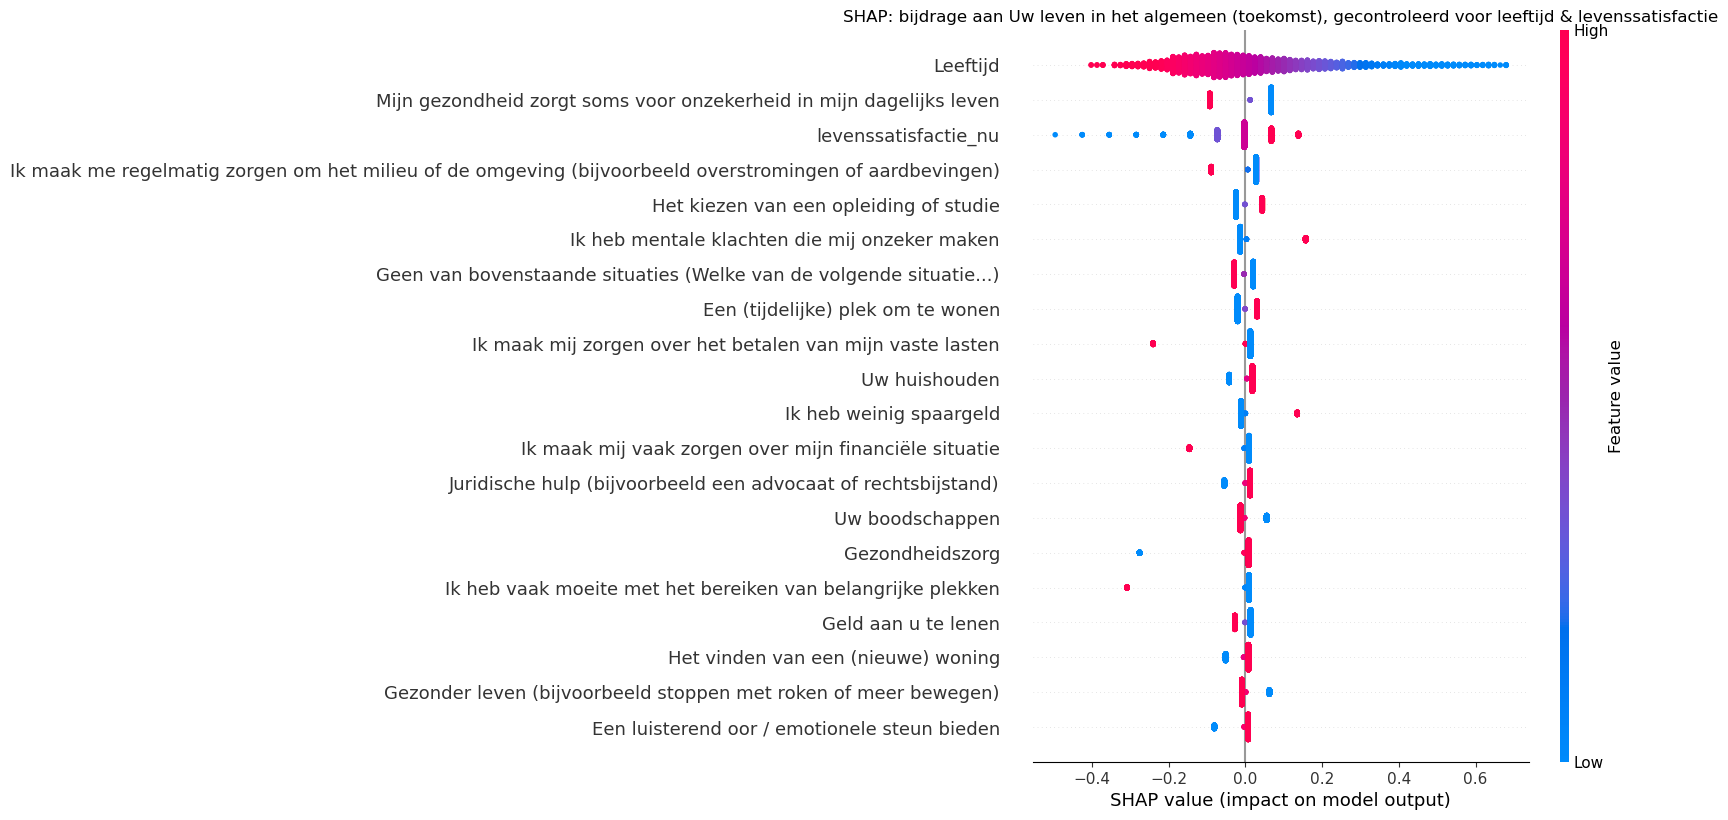


Gemiddelde |SHAP-waarde| per feature:
Leeftijd                                                                                                         0.147289
Mijn gezondheid zorgt soms voor onzekerheid in mijn dagelijks leven                                              0.075794
levenssatisfactie_nu                                                                                             0.048957
Ik maak me regelmatig zorgen om het milieu of de omgeving (bijvoorbeeld overstromingen of aardbevingen)          0.039578
Het kiezen van een opleiding of studie                                                                           0.031119
Ik heb mentale klachten die mij onzeker maken                                                                    0.027331
Geen van bovenstaande situaties (Welke van de volgende situatie...)                                              0.024555
Een (tijdelijke) plek om te wonen                                                                          

In [38]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# â”€â”€ 1. Doelvariabele: toekomstverwachting, "leven in het algemeen" â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
target_subject = [c for c in toekomst_df.columns if "leven in het algemeen" in c.lower()]
assert len(target_subject) == 1, f"Verwachtte 1 match, kreeg: {target_subject}"
target_subject = target_subject[0]
print("Doelvariabele:", target_subject, "(toekomst)")

# â”€â”€ 2. Life satisfaction nu, "leven in het algemeen" (controlevariabele) â”€â”€â”€â”€
tev_subject = [c for c in tevreden_df.columns if "leven in het algemeen" in c.lower()]
assert len(tev_subject) == 1
tev_subject = tev_subject[0]

# â”€â”€ 3. Onafhankelijke vars: hulp-netwerk / weet-waar-hulp / situaties â”€â”€â”€â”€â”€â”€â”€
hulp_netwerk_cols = [c for c in df.columns if "zou kunnen helpen met" in c.lower() or "terechtkunt" in c.lower()]
weet_waar_hulp_cols = [c for c in df.columns if "welke organisaties ik terecht kan" in c.lower()]
situaties_van_toepassing_cols = [c for c in df.columns if "situaties zijn op u van toepassing" in c.lower() or "situaties is op u van toepassing" in c.lower()]
alle_cols = hulp_netwerk_cols + weet_waar_hulp_cols + situaties_van_toepassing_cols

bin_df = pd.DataFrame(index=df.index)
full_labels = {}
for c in alle_cols:
    if df[c].dropna().isin([0, 1]).all() or df[c].dtype == bool:
        vals = df[c].astype(float)
    else:
        vals = df[c].astype(str).str.lower().str.contains("ja", na=False, regex=False).astype(float)
        vals[df[c].isna()] = np.nan
    label = c.split(" - ")[-1].strip()
    if label in full_labels.values():
        label = f"{label} ({c.split('?')[0][:30]}...)"
    full_labels[c] = label
    bin_df[label] = vals

predictor_labels = list(full_labels.values())

# â”€â”€ 4. Regressiedataframe opbouwen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
reg_df = pd.DataFrame({
    "score": toekomst_df[target_subject],
    "Leeftijd": df["Leeftijd"],
    "levenssatisfactie_nu": tevreden_df[tev_subject],
})
for label in predictor_labels:
    reg_df[label] = bin_df[label]

# Alleen rijen droppen waar de DOELVARIABELE mist
reg_df = reg_df.dropna(subset=["score"])
print(f"\nN vÃ³Ã³r imputatie (na dropna op target): {len(reg_df)}")

# â”€â”€ 5. Mean-imputatie voor missende predictoren â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
predictor_cols = [c for c in reg_df.columns if c != "score"]
n_missing_per_col = reg_df[predictor_cols].isna().sum()
print("\nMissende waarden per predictor (vÃ³Ã³r imputatie):")
print(n_missing_per_col[n_missing_per_col > 0])

reg_df[predictor_cols] = reg_df[predictor_cols].astype(float)
reg_df[predictor_cols] = reg_df[predictor_cols].fillna(reg_df[predictor_cols].mean())

print(f"\nN na imputatie: {len(reg_df)}")

# â”€â”€ 6. OLS regressie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
X = reg_df.drop(columns="score")
y = reg_df["score"]

X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()
print(model.summary())

# â”€â”€ 7. SHAP decompositie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
lr = LinearRegression().fit(X, y)
explainer = shap.LinearExplainer(lr, X)
shap_values = explainer(X)

shap.summary_plot(shap_values, X, show=False)
plt.title(f"SHAP: bijdrage aan {target_subject} (toekomst), gecontroleerd voor leeftijd & levenssatisfactie")
plt.tight_layout()
plt.savefig("shap_summary_toekomst_algemeen_hulp_bestaanszekerheid.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nGemiddelde |SHAP-waarde| per feature:")
print(pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns).sort_values(ascending=False))

In [39]:
import pandas as pd
weight_col = "weegfactor"

# Gebruik regioprovincie (= hernoemde Provincie kolom) i.p.v. gemeente
# en Opleiding (3 niveaus) (hernoemde opleiding3 kolom)
export_cols = ['regioprovincie', 'leeftijd categorie', 'Opleiding (3 niveaus)', weight_col]
avail = [c for c in export_cols if c in df.columns]
missing = [c for c in export_cols if c not in df.columns]
if missing:
    print(f"Let op: kolommen niet gevonden in df: {missing}")

export_df = (
    df[avail]
    .dropna(subset=avail[:-1])
    .drop_duplicates(subset=avail[:-1])
    .sort_values(avail[:-1])
    .rename(columns={
        'regioprovincie':       'Provincie',
        'leeftijd categorie':   'Leeftijd',
        'Opleiding (3 niveaus)':'Opleiding',
        weight_col:             'Weegfactor',
    })
    .reset_index(drop=True)
)
export_df.to_excel("weegtabel_export.xlsx", index=False)
print(f"Weegtabel geëxporteerd: {len(export_df)} rijen naar weegtabel_export.xlsx")

Weegtabel geëxporteerd: 26 rijen naar weegtabel_export.xlsx


In [40]:
# â”€â”€ 1. Kolomnamen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
invloed_cols = [c for c in df.columns if "hoeveel invloed" in c.lower()]
print(f"Aantal 'invloed' kolommen: {len(invloed_cols)}")
for c in invloed_cols:
    print(" -", c)

# â”€â”€ 2. Unieke waarden per kolom (check of schaal consistent is) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print("\n=== Unieke waarden per invloed-kolom ===")
for c in invloed_cols:
    print(f"\n{c}:")
    print(df[c].value_counts(dropna=False).sort_index())

# â”€â”€ 3. Preview van dummy-encoding voor 1 kolom â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
voorbeeld_col = invloed_cols[0]
dummies_preview = pd.get_dummies(df[voorbeeld_col], prefix="invloed", drop_first=True)
print(f"\n=== Dummy-encoding preview voor '{voorbeeld_col}' ===")
print(dummies_preview.head(10))
print("\nKolommen na dummy-encoding:", dummies_preview.columns.tolist())

Aantal 'invloed' kolommen: 9
 - Hoeveel invloed denkt u dat u heeft op: - Uw leven in het algemeen
 - Hoeveel invloed denkt u dat u heeft op: - Uw financiële situatie (uw geldzaken)
 - Hoeveel invloed denkt u dat u heeft op: - Uw lichamelijke gezondheid
 - Hoeveel invloed denkt u dat u heeft op: - Uw psychische gezondheid
 - Hoeveel invloed denkt u dat u heeft op: - Uw werk en/of andere dagelijkse bezigheden
 - Hoeveel invloed denkt u dat u heeft op: - Uw hoeveelheid vrije tijd
 - Hoeveel invloed denkt u dat u heeft op: - Uw woning of woonruimte
 - Hoeveel invloed denkt u dat u heeft op: - Uw buurt of wijk (directe woonomgeving)
 - Hoeveel invloed denkt u dat u heeft op: - Uw sociale contacten (familie, vrienden, kennissen etc.)

=== Unieke waarden per invloed-kolom ===

Hoeveel invloed denkt u dat u heeft op: - Uw leven in het algemeen:
Hoeveel invloed denkt u dat u heeft op: - Uw leven in het algemeen
Een beetje invloed    1561
Geen invloed           170
Veel invloed          1915
We

Doelvariabele: 'ontevreden_en_pessimistisch' vs. overige groepen
  116 van 3737 respondenten (3.1%)

Resterende kolommen: 141 numeriek, 99 categorisch (3 overgeslagen wegens >20 categorieen)
  Overgeslagen: ['Voornaam', 'Wat is uw postcode? (bv. 9640 PA)<br>\n<br>\n<em>Let op: 4 cijfers gevolgd door spatie en 2 hoofdletters</em>', 'Zijn er andere onderwerpen waarover u zorgen voor de toekomst heeft, en waarom?']

N respondenten: 3737  |  Totaal predictoren na encoding: 500


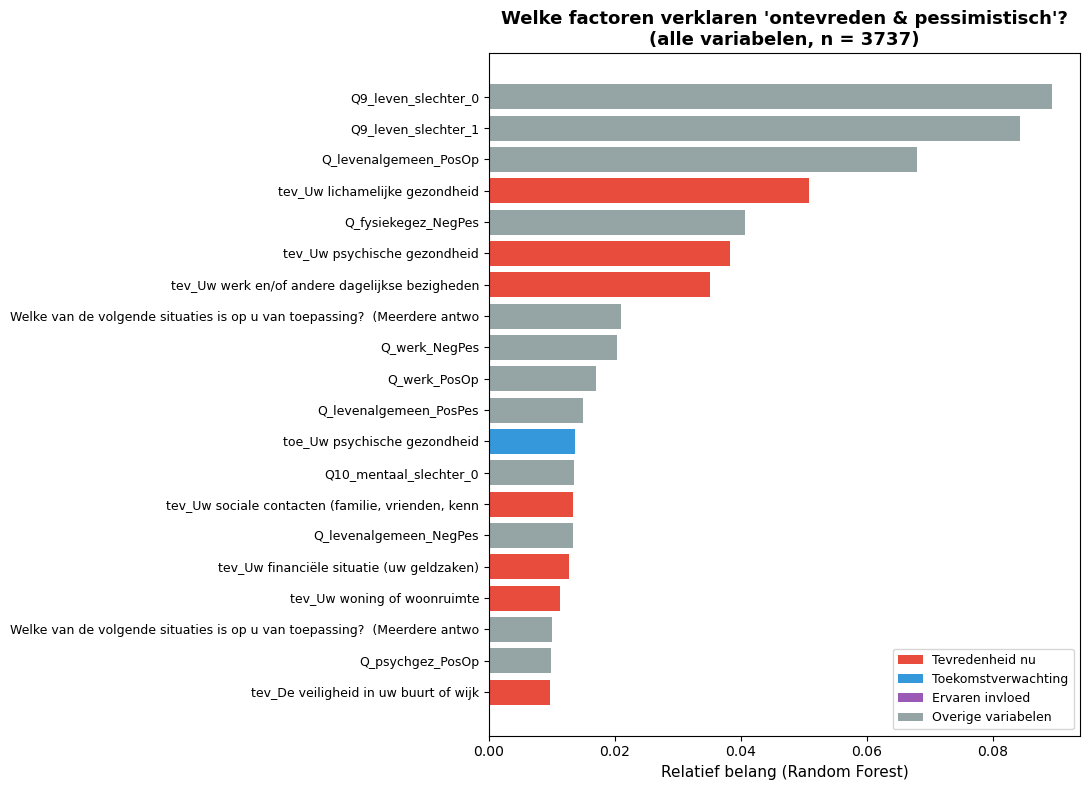


Top 15 verklarende factoren:
   1. Q9_leven_slechter_0                                                     belang=0.0894
   2. Q9_leven_slechter_1                                                     belang=0.0844
   3. Q_levenalgemeen_PosOp                                                   belang=0.0679
   4. tev_Uw lichamelijke gezondheid                                          belang=0.0509
   5. Q_fysiekegez_NegPes                                                     belang=0.0407
   6. tev_Uw psychische gezondheid                                            belang=0.0383
   7. tev_Uw werk en/of andere dagelijkse bezigheden                          belang=0.0351
   8. Welke van de volgende situaties is op u van toepassing?  (Meerdere ant  belang=0.0210
   9. Q_werk_NegPes                                                           belang=0.0204
  10. Q_werk_PosOp                                                            belang=0.0169
  11. Q_levenalgemeen_PosPes                      

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

# -- 1. Doelvariabele
target_col   = "situatie_uw_leven_in_het_algemeen"
target_label = "ontevreden_en_pessimistisch"

y = (df[target_col] == target_label).astype(int)
print(f"Doelvariabele: '{target_label}' vs. overige groepen")
print(f"  {y.sum()} van {len(y)} respondenten ({y.mean()*100:.1f}%)")

# -- 2. Predictoren: tevreden + toekomst (numeriek) + alle overige df-kolommen
# 2a. Numerieke tevredenheid- en toekomstscores (al omgezet naar 1-10)
feat_tev = tevreden_df.copy()
feat_tev.columns = ["tev_" + c[:45] for c in feat_tev.columns]
feat_tev.index = df.index

feat_toe = toekomst_df.copy()
feat_toe.columns = ["toe_" + c[:45] for c in feat_toe.columns]
feat_toe.index = df.index

# Verwijder de kolommen waaruit de doelvariabele is opgebouwd
# (situatie_uw_leven_in_het_algemeen = combo van tevredenheid + toekomst "leven algemeen")
feat_tev = feat_tev[[c for c in feat_tev.columns if "leven in het algemeen" not in c.lower()]]
feat_toe = feat_toe[[c for c in feat_toe.columns if "leven in het algemeen" not in c.lower()]]

# 2b. Alle overige df-kolommen - sluit uit: target, andere situatie_* (data-lekkage),
#     de originele tevreden/toekomst tekst-kolommen, gewichten, admin
tevreden_orig = {c for c in df.columns if "hoe tevreden u bent met" in c.lower()}
toekomst_orig = {c for c in df.columns if "komende 5 jaar" in c.lower()}

exclude_cols = (
    {c for c in df.columns if c.startswith("situatie_")} |
    {c for c in df.columns if "weeg" in c.lower()} |
    {"_bronbestand", "Reactiestatus", "gemcode2021", "gemeente"} |
    tevreden_orig | toekomst_orig
)
remaining_cols = [c for c in df.columns if c not in exclude_cols]

cat_cols = [c for c in remaining_cols if df[c].dtype == object]
num_cols = [c for c in remaining_cols if df[c].dtype != object]

# Categorische kolommen: alleen als <= 20 unieke waarden (anders te veel dummies)
cat_ok   = [c for c in cat_cols if df[c].nunique() <= 20]
cat_skip = [c for c in cat_cols if df[c].nunique() > 20]
print(f"\nResterende kolommen: {len(num_cols)} numeriek, {len(cat_ok)} categorisch "
      f"({len(cat_skip)} overgeslagen wegens >20 categorieen)")
if cat_skip:
    print(f"  Overgeslagen: {cat_skip}")

X_rem_num = df[num_cols].copy()
X_rem_cat = pd.get_dummies(df[cat_ok], drop_first=False, dummy_na=False)

X = pd.concat([feat_tev, feat_toe, X_rem_num, X_rem_cat], axis=1)

# -- 3. Opschonen
valid = y.notna() & df[target_col].notna()
X_clean = X[valid].astype(float)
y_clean = y[valid]

for col in X_clean.columns:
    X_clean[col] = X_clean[col].fillna(X_clean[col].median())

print(f"\nN respondenten: {len(y_clean)}  |  Totaal predictoren na encoding: {X_clean.shape[1]}")

# -- 4. Random Forest
rf = RandomForestClassifier(n_estimators=400, max_depth=7, random_state=42,
                             class_weight="balanced", n_jobs=-1)
rf.fit(X_clean, y_clean)

importances = (pd.Series(rf.feature_importances_, index=X_clean.columns)
               .sort_values(ascending=False))
top20 = importances.head(20)

# -- 5. Kleur per variabeletype
def get_color(col):
    if col.startswith("tev_"):           return "#e74c3c"
    if col.startswith("toe_"):           return "#3498db"
    if "invloed" in col.lower():         return "#9b59b6"
    return "#95a5a6"

# -- 6. Visualisatie
fig, ax = plt.subplots(figsize=(11, 8))
colors = [get_color(c) for c in top20.index[::-1]]

ax.barh(range(len(top20)), top20.values[::-1], color=colors)
ax.set_yticks(range(len(top20)))
ax.set_yticklabels([c[:72] for c in top20.index[::-1]], fontsize=9)
ax.set_xlabel("Relatief belang (Random Forest)", fontsize=11)
ax.set_title(
    f"Welke factoren verklaren 'ontevreden & pessimistisch'?\n(alle variabelen, n = {len(y_clean)})",
    fontsize=13, fontweight="bold")

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#e74c3c", label="Tevredenheid nu"),
    Patch(facecolor="#3498db", label="Toekomstverwachting"),
    Patch(facecolor="#9b59b6", label="Ervaren invloed"),
    Patch(facecolor="#95a5a6", label="Overige variabelen"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("ontevreden_pessimistisch_factoren.png", dpi=150, bbox_inches="tight")
plt.show()

# -- 7. Tekstoverzicht
print("\nTop 15 verklarende factoren:")
for i, (col, imp) in enumerate(importances.head(15).items(), 1):
    print(f"  {i:2d}. {col[:70]:<70s}  belang={imp:.4f}")

## Analyse A – Demografisch profiel per situatiegroep

Gewogen N per situatiegroep (leven in het algemeen):
  Tevreden & stabiel                 : n=2,392  (72.2%)
  Tevreden & pessimistisch           : n=558  (16.8%)
  Ontevreden & optimistisch          : n=204  (6.2%)
  Ontevreden & pessimistisch         : n=160  (4.8%)

=== Demografisch profiel (%, gewogen) ===
Groep                                                  tevreden_en_stabiel  tevreden_en_pessimistisch  ontevreden_en_optimistisch  ontevreden_en_pessimistisch
Variabele             Categorie                                                                                                                               
Geslacht              Een man                                         27.6                       33.8                        30.1                         37.4
                      Een vrouw                                       23.3                       23.7                        30.3                         34.5
                      Man                           

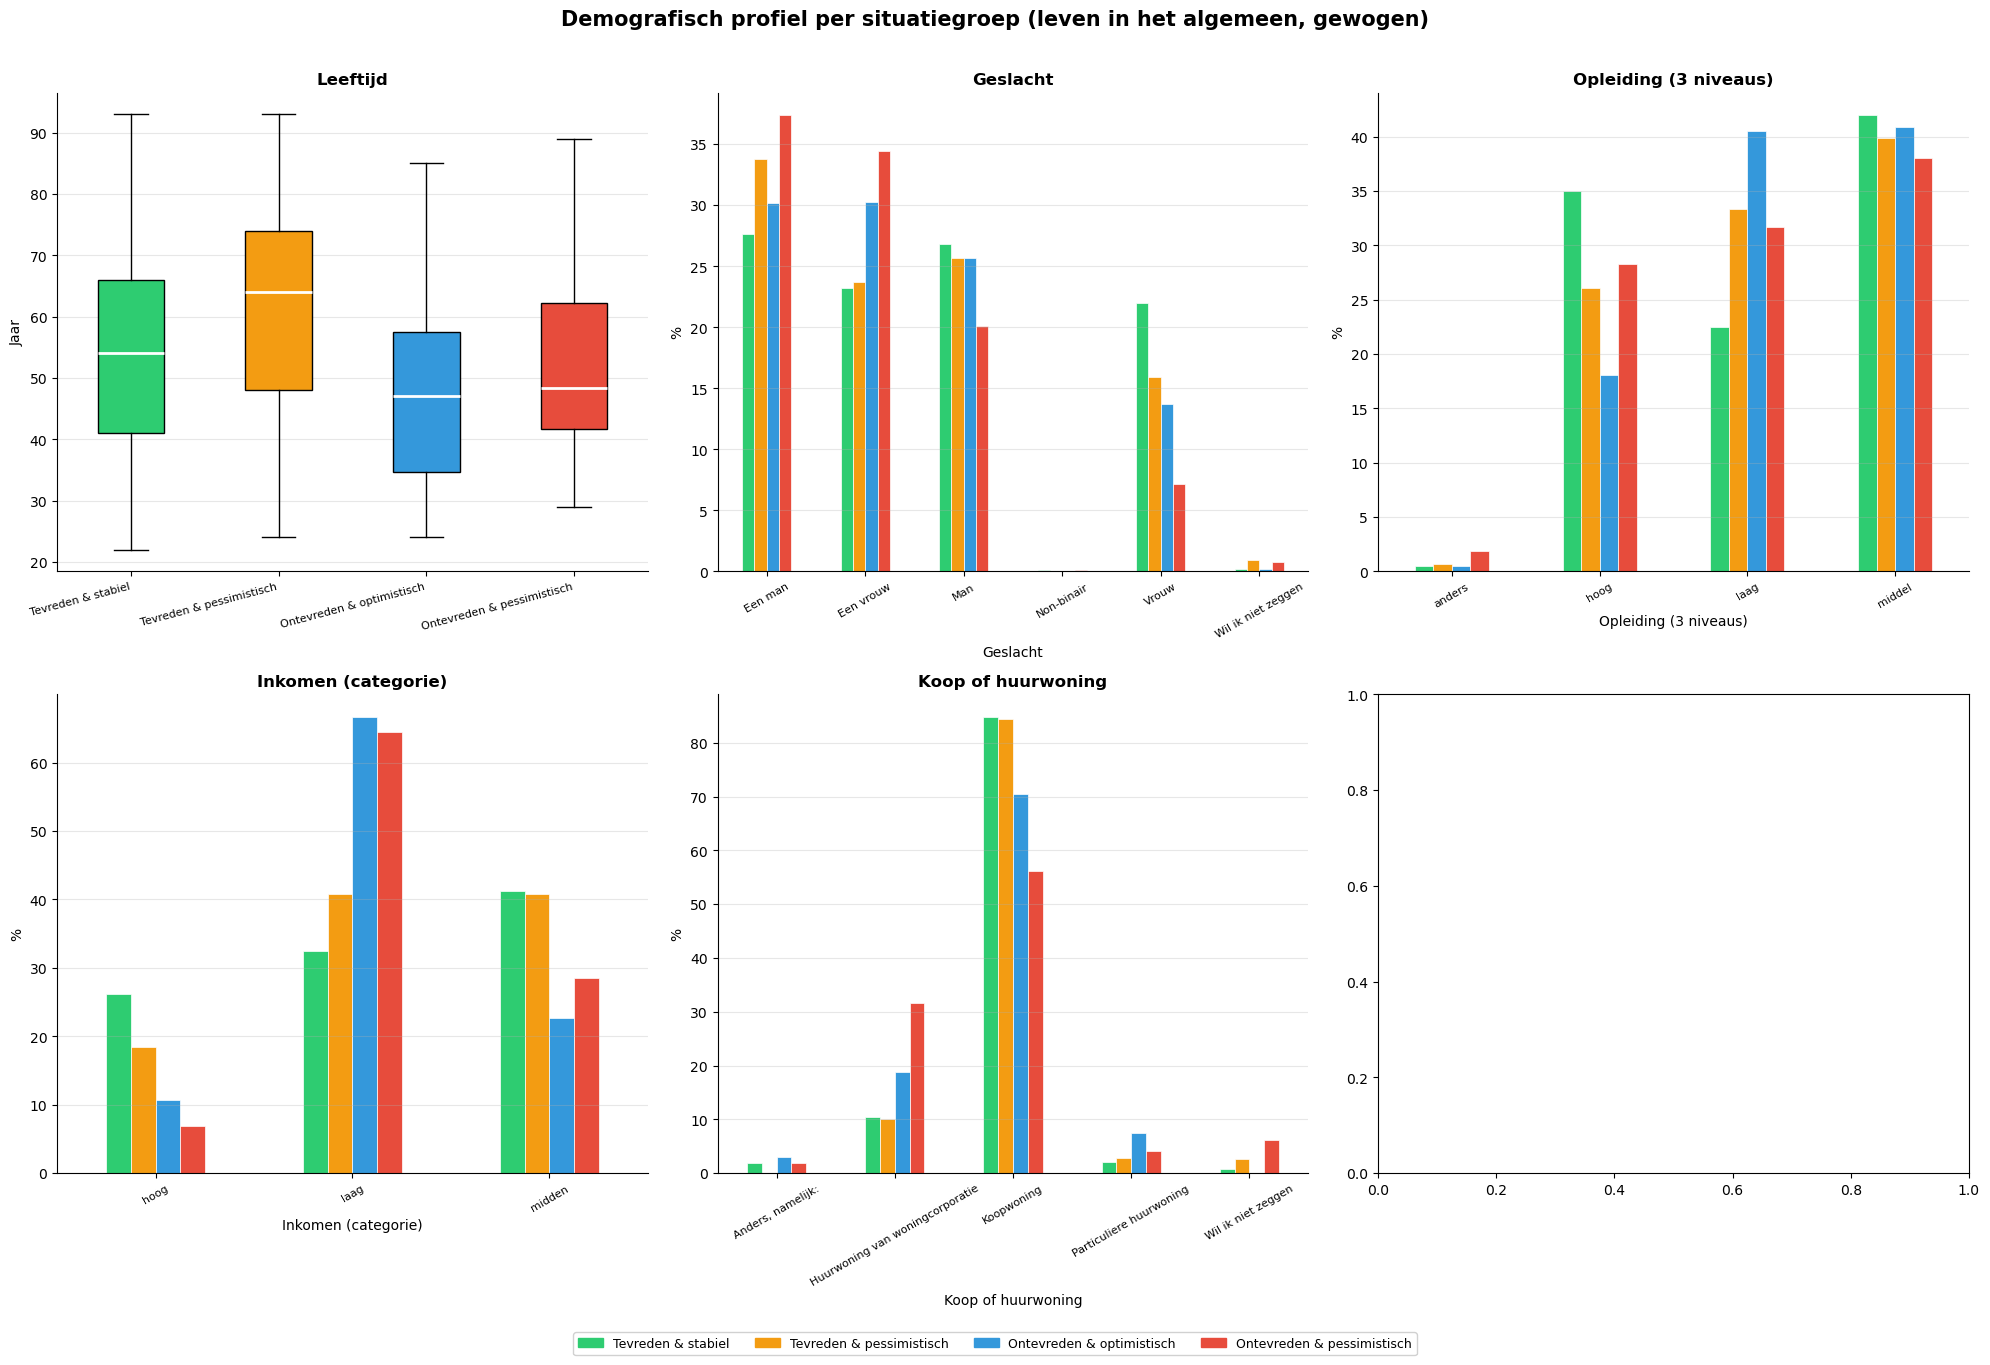


Figuur opgeslagen: demografisch_profiel_situatiegroepen.png


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ════════════════════════════════════════════════════════════════════════════════
# ANALYSE A: Demografisch profiel per situatiegroep (leven in het algemeen)
# Vergelijk: wie valt in welke groep? (leeftijd, geslacht, opleiding, etc.)
# ════════════════════════════════════════════════════════════════════════════════

situatie_col = "situatie_uw_leven_in_het_algemeen"
weight_col   = "weegfactor"
cat_order    = ["tevreden_en_stabiel", "tevreden_en_pessimistisch",
                "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]
cat_labels   = {
    "tevreden_en_stabiel":         "Tevreden & stabiel",
    "tevreden_en_pessimistisch":   "Tevreden & pessimistisch",
    "ontevreden_en_optimistisch":  "Ontevreden & optimistisch",
    "ontevreden_en_pessimistisch": "Ontevreden & pessimistisch",
}
colors_g = {
    "tevreden_en_stabiel":         "#2ecc71",
    "tevreden_en_pessimistisch":   "#f39c12",
    "ontevreden_en_optimistisch":  "#3498db",
    "ontevreden_en_pessimistisch": "#e74c3c",
}

demo_vars = [v for v in [
    "Leeftijd", "Geslacht", "Opleiding (3 niveaus)",
    "Inkomen (categorie)", "Koop of huurwoning", "stadplatteland",
] if v in df.columns]

sub_main = df[[situatie_col, weight_col] + demo_vars].dropna(subset=[situatie_col])

# ── Gewogen N per groep ──────────────────────────────────────────────────────
groep_n = {g: df.loc[df[situatie_col] == g, weight_col].sum() for g in cat_order}
total_n = sum(groep_n.values())
print("Gewogen N per situatiegroep (leven in het algemeen):")
for g in cat_order:
    pct = groep_n[g] / total_n * 100
    print(f"  {cat_labels[g]:<35s}: n={groep_n[g]:,.0f}  ({pct:.1f}%)")

# ── Bouw profiel-tabel ────────────────────────────────────────────────────────
def wq(v, w, q):
    v, w = np.asarray(v, float), np.asarray(w, float)
    ok = ~(np.isnan(v) | np.isnan(w))
    v, w = v[ok], w[ok]
    if len(v) == 0:
        return np.nan
    o = np.argsort(v); v, w = v[o], w[o]
    cw = (np.cumsum(w) - 0.5 * w) / w.sum()
    return float(np.interp(q, cw, v))

profile_rows = []
for var in demo_vars:
    sub = sub_main[[situatie_col, var, weight_col]].dropna(subset=[var])
    if var == "Leeftijd":
        for g in cat_order:
            grp = sub[sub[situatie_col] == g]
            if len(grp) == 0:
                continue
            wavg = np.average(grp["Leeftijd"].astype(float),
                              weights=grp[weight_col].astype(float))
            wmed = wq(grp["Leeftijd"].values, grp[weight_col].values, 0.5)
            profile_rows.append({
                "Variabele": "Leeftijd", "Categorie": "Gemiddelde",
                "Groep": g, "Waarde": round(wavg, 1),
            })
            profile_rows.append({
                "Variabele": "Leeftijd", "Categorie": "Mediaan",
                "Groep": g, "Waarde": round(wmed, 1),
            })
    else:
        ct = sub.groupby([situatie_col, var])[weight_col].sum().unstack(fill_value=0)
        ct_pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
        for cat in ct_pct.columns:
            for g in cat_order:
                val = float(ct_pct.loc[g, cat]) if g in ct_pct.index else 0.0
                profile_rows.append({
                    "Variabele": var, "Categorie": str(cat),
                    "Groep": g, "Waarde": val,
                })

profile_long = pd.DataFrame(profile_rows)
profile_wide = (
    profile_long
    .pivot_table(index=["Variabele", "Categorie"], columns="Groep", values="Waarde")
    .reindex(columns=[c for c in cat_order if c in profile_long["Groep"].unique()])
)
print("\n=== Demografisch profiel (%, gewogen) ===")
print(profile_wide.to_string())

# ── Visualisatie ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
fig.suptitle("Demografisch profiel per situatiegroep (leven in het algemeen, gewogen)",
             fontsize=15, fontweight="bold", y=1.01)
axes_flat = axes.flatten()

# Leeftijd: gewogen boxplot
ax = axes_flat[0]
bxp_stats = []
for g in cat_order:
    grp = sub_main[sub_main[situatie_col] == g][["Leeftijd", weight_col]].dropna()
    if len(grp) == 0:
        bxp_stats.append({"med": 0, "q1": 0, "q3": 0, "whislo": 0, "whishi": 0, "fliers": []})
        continue
    v = grp["Leeftijd"].astype(float).values
    w = grp[weight_col].astype(float).values
    bxp_stats.append({
        "med": wq(v, w, 0.5), "q1": wq(v, w, 0.25), "q3": wq(v, w, 0.75),
        "whislo": float(v.min()), "whishi": float(v.max()), "fliers": [],
    })
bp = ax.bxp(bxp_stats, patch_artist=True, medianprops=dict(color="white", linewidth=2))
for patch, g in zip(bp["boxes"], cat_order):
    patch.set_facecolor(colors_g[g])
ax.set_xticks(range(1, len(cat_order) + 1))
ax.set_xticklabels([cat_labels[g] for g in cat_order], fontsize=8, rotation=15, ha="right")
ax.set_title("Leeftijd", fontweight="bold")
ax.set_ylabel("Jaar")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

# Categorische vars
for idx, var in enumerate([v for v in demo_vars if v != "Leeftijd"][:5]):
    ax = axes_flat[idx + 1]
    sub = sub_main[[situatie_col, var, weight_col]].dropna(subset=[var])
    ct = sub.groupby([situatie_col, var])[weight_col].sum().unstack(fill_value=0)
    ct_pct = (ct.div(ct.sum(axis=1), axis=0) * 100).reindex(cat_order).dropna(how="all")
    ct_pct.T.plot(kind="bar", ax=ax,
                  color=[colors_g[g] for g in ct_pct.index],
                  edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(var, fontweight="bold")
    ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors_g[g]) for g in cat_order]
fig.legend(handles, [cat_labels[g] for g in cat_order],
           loc="lower center", ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.03), framealpha=0.9)
plt.tight_layout()
plt.savefig("demografisch_profiel_situatiegroepen.png", dpi=150, bbox_inches="tight")
plt.show()

# Bewaar voor Excel export
_excel_demografie = profile_wide.copy()
print("\nFiguur opgeslagen: demografisch_profiel_situatiegroepen.png")

## Analyse B – Variantiedecompositie levenssatisfactie

Doelvariabele: Uw leven in het algemeen
Aantal predictor-domeinen: 14
N respondenten (na dropna doelvariabele): 3728

=== Hiërarchische R² ===
  Model 1 – Domein-tevredenheid alleen : R² = 0.619  (61.9%)
  Model 2 – + Toekomstverwachting      : R² = 0.624  (+0.4%)
  Model 3 – + Ervaren invloed           : R² = 0.625  (+0.2%)
  Onverklaard                           :       37.5%


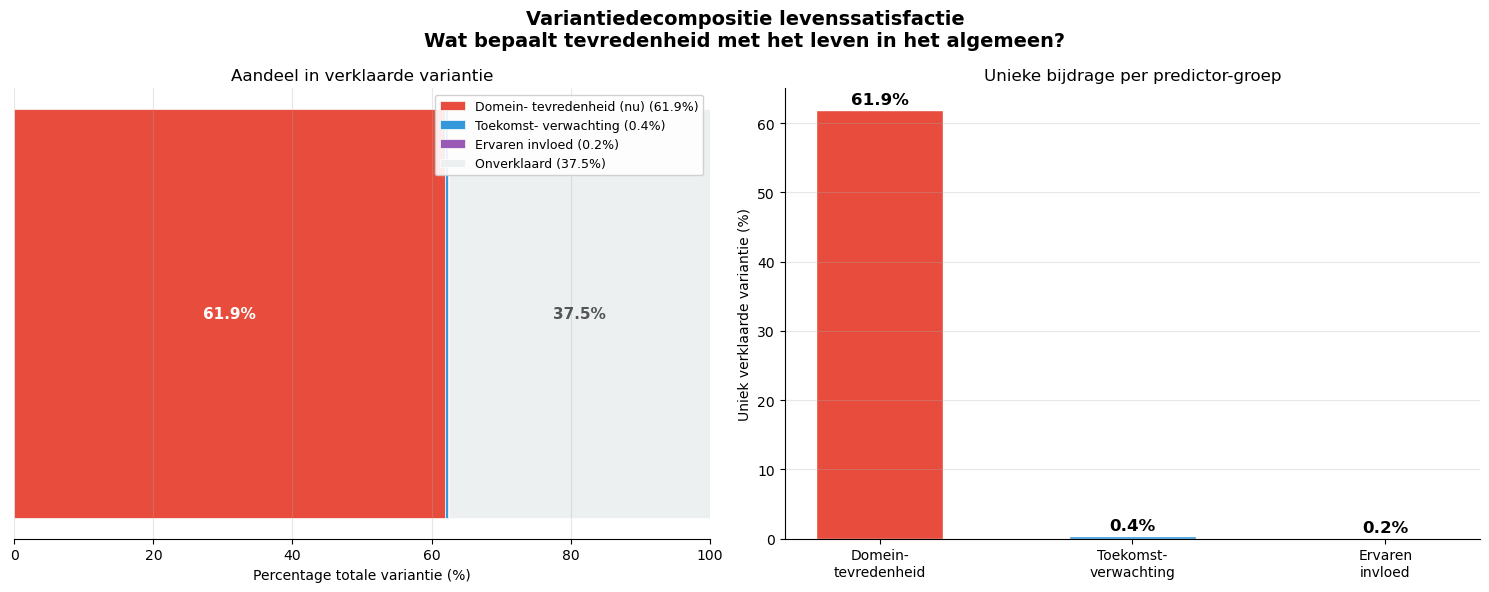


Figuur opgeslagen: variantiedecompositie_levenssatisfactie.png
                  Predictor-groep  R2_bijdrage_%  Cumulatief_R2
         Domein-tevredenheid (nu)          61.92         0.6192
Toekomstverwachting (uniek extra)           0.44         0.6236
    Ervaren invloed (uniek extra)           0.17         0.6252
                      Onverklaard          37.48         1.0000


In [43]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ════════════════════════════════════════════════════════════════════════════════
# ANALYSE B: Variantiedecompositie levenssatisfactie
# Hoeveel % verklaart: domein-tevredenheid (nu) | toekomstverwachting | invloed?
# ════════════════════════════════════════════════════════════════════════════════

weight_col = "weegfactor"

target_subj = [c for c in tevreden_df.columns if "leven in het algemeen" in c.lower()][0]
pred_subjects = [s for s in subjects if s != target_subj]

print(f"Doelvariabele: {target_subj}")
print(f"Aantal predictor-domeinen: {len(pred_subjects)}")

# ── Bouw regressie-dataframe ─────────────────────────────────────────────────
rdf = pd.DataFrame({"y": tevreden_df[target_subj]})

dom_cols = []
for s in pred_subjects:
    c = f"dom_{s[:50]}"
    rdf[c] = tevreden_df[s]
    dom_cols.append(c)

toe_cols = []
for s in pred_subjects:
    if s in toekomst_df.columns:
        c = f"toe_{s[:50]}"
        rdf[c] = toekomst_df[s]
        toe_cols.append(c)

inv_cols = list(invloed_dummy_cols)
for d in inv_cols:
    rdf[d] = df[d]

rdf = rdf.dropna(subset=["y"])
all_pred_cols = dom_cols + toe_cols + inv_cols
for c in all_pred_cols:
    rdf[c] = pd.to_numeric(rdf[c], errors="coerce")
    rdf[c] = rdf[c].fillna(rdf[c].mean())

y = rdf["y"].astype(float)
print(f"N respondenten (na dropna doelvariabele): {len(y)}")

def fit_r2(cols):
    X = sm.add_constant(rdf[cols].astype(float))
    return sm.OLS(y, X).fit().rsquared

r2_dom  = fit_r2(dom_cols)
r2_dt   = fit_r2(dom_cols + toe_cols)   if toe_cols else r2_dom
r2_dti  = fit_r2(dom_cols + toe_cols + inv_cols) if inv_cols else r2_dt

incr_dom = r2_dom
incr_toe = r2_dt  - r2_dom
incr_inv = r2_dti - r2_dt
unexpl   = 1.0    - r2_dti

print("\n=== Hiërarchische R² ===")
print(f"  Model 1 – Domein-tevredenheid alleen : R² = {r2_dom:.3f}  ({r2_dom*100:.1f}%)")
print(f"  Model 2 – + Toekomstverwachting      : R² = {r2_dt:.3f}  (+{incr_toe*100:.1f}%)")
print(f"  Model 3 – + Ervaren invloed           : R² = {r2_dti:.3f}  (+{incr_inv*100:.1f}%)")
print(f"  Onverklaard                           :       {unexpl*100:.1f}%")

# ── Visualisatie ──────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Variantiedecompositie levenssatisfactie\n"
             "Wat bepaalt tevredenheid met het leven in het algemeen?",
             fontsize=14, fontweight="bold")

comp_data = {
    "Domein-\ntevredenheid (nu)": (incr_dom * 100, "#e74c3c"),
    "Toekomst-\nverwachting":      (incr_toe * 100, "#3498db"),
    "Ervaren\ninvloed":            (incr_inv * 100, "#9b59b6"),
    "Onverklaard":                  (unexpl   * 100, "#ecf0f1"),
}

left = 0.0
for label, (val, color) in comp_data.items():
    ax1.barh(["Levenssatisfactie"], [val], left=left, color=color,
             label=f"{label.replace(chr(10), ' ')} ({val:.1f}%)", edgecolor="white", linewidth=0.5)
    if val > 4:
        ax1.text(left + val / 2, 0, f"{val:.1f}%",
                 ha="center", va="center", fontsize=11, fontweight="bold",
                 color="white" if color != "#ecf0f1" else "#555")
    left += val
ax1.set_xlim(0, 100)
ax1.set_xlabel("Percentage totale variantie (%)")
ax1.set_title("Aandeel in verklaarde variantie")
ax1.legend(loc="upper right", fontsize=9, framealpha=0.9)
ax1.spines[["top", "right", "left"]].set_visible(False)
ax1.set_yticks([])
ax1.grid(axis="x", alpha=0.3)

# Incrementele R² als staafdiagram
labels_bar = ["Domein-\ntevredenheid", "Toekomst-\nverwachting", "Ervaren\ninvloed"]
vals_bar   = [incr_dom * 100, incr_toe * 100, incr_inv * 100]
cols_bar   = ["#e74c3c", "#3498db", "#9b59b6"]
bars = ax2.bar(labels_bar, vals_bar, color=cols_bar, edgecolor="white", width=0.5)
for bar, val in zip(bars, vals_bar):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
             f"{val:.1f}%", ha="center", va="bottom", fontsize=12, fontweight="bold")
ax2.set_ylabel("Uniek verklaarde variantie (%)")
ax2.set_title("Unieke bijdrage per predictor-groep")
ax2.tick_params(axis="x", labelsize=10)
ax2.grid(axis="y", alpha=0.3)
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("variantiedecompositie_levenssatisfactie.png", dpi=150, bbox_inches="tight")
plt.show()

# Bewaar voor Excel export
_excel_vardecomp = pd.DataFrame({
    "Predictor-groep": [
        "Domein-tevredenheid (nu)",
        "Toekomstverwachting (uniek extra)",
        "Ervaren invloed (uniek extra)",
        "Onverklaard",
    ],
    "R2_bijdrage_%": [round(v * 100, 2) for v in
                      [incr_dom, incr_toe, incr_inv, unexpl]],
    "Cumulatief_R2": [round(v, 4) for v in [r2_dom, r2_dt, r2_dti, 1.0]],
})
print("\nFiguur opgeslagen: variantiedecompositie_levenssatisfactie.png")
print(_excel_vardecomp.to_string(index=False))

## Analyse C – Beschermende factoren

=== Gemiddelde domein-tevredenheid (gewogen) ===
Groep                                                                                                                    Ontevreden & pessimistisch  Tevreden & stabiel  Verschil (A-B)
Domein                                                                                                                                                                                 
Uw lichamelijke gezondheid                                                                                                                     4.72                7.38            2.66
Uw financiële situatie (uw geldzaken)                                                                                                          5.44                7.96            2.53
Uw werk en/of andere dagelijkse bezigheden                                                                                                     5.30                7.79            2.49
Uw psychische gezondheid       

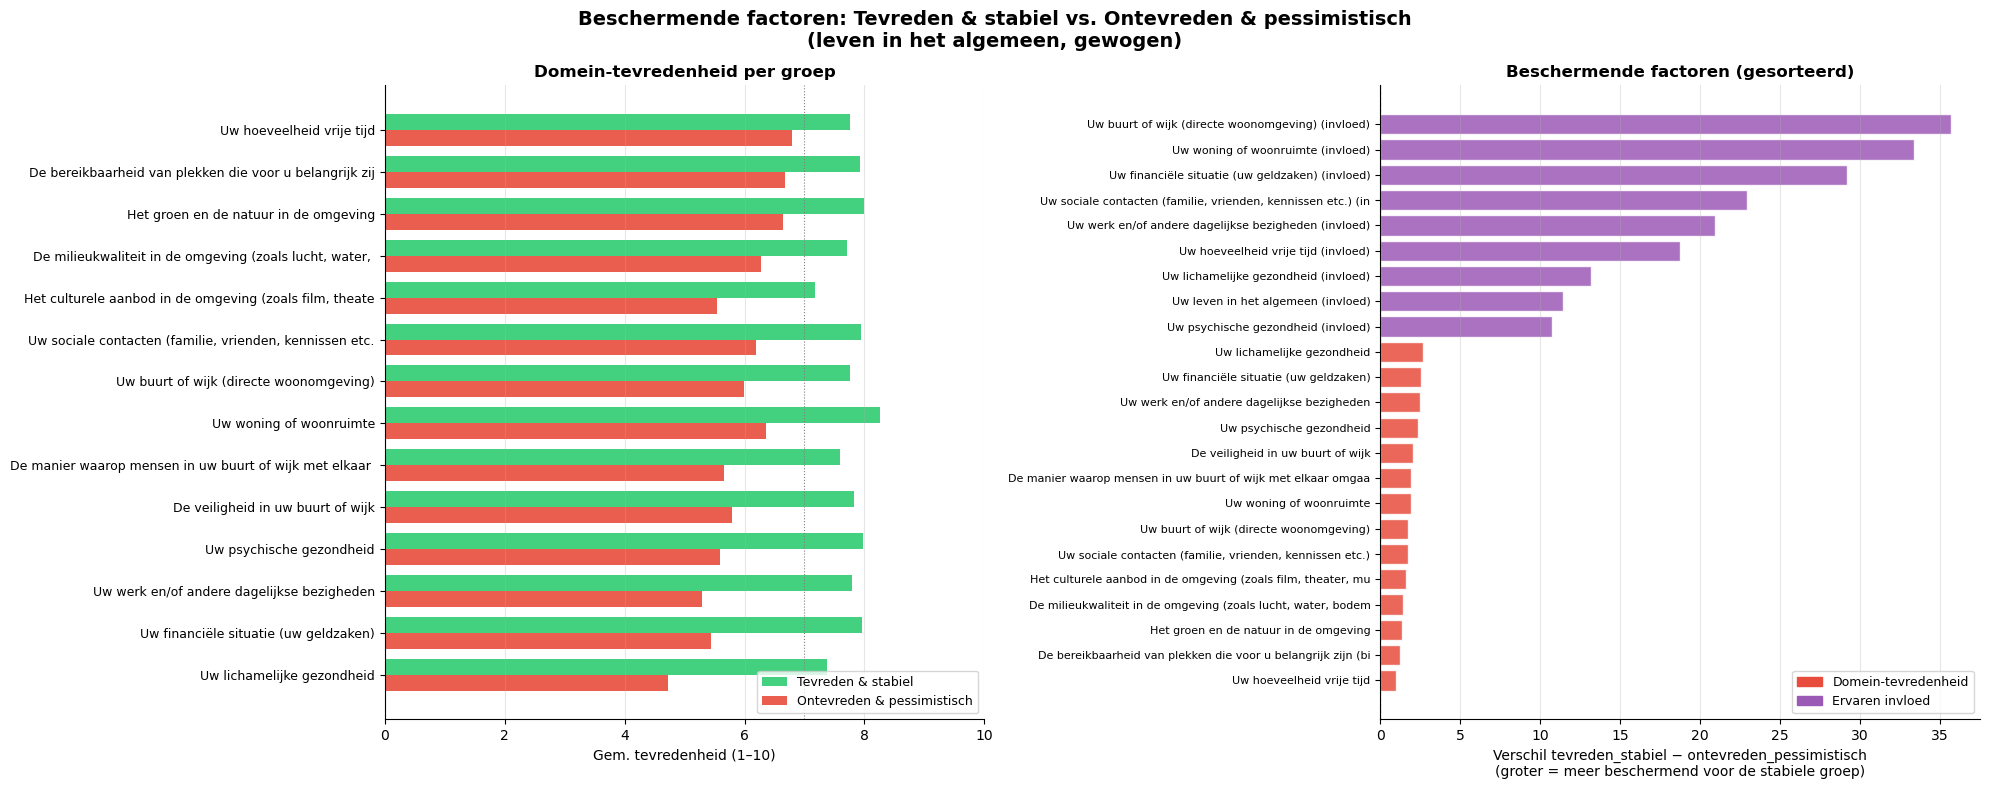


Figuur opgeslagen: beschermende_factoren.png


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ════════════════════════════════════════════════════════════════════════════════
# ANALYSE C: Beschermende factoren
# Vergelijk tevreden_stabiel vs ontevreden_pessimistisch op domeinen + invloed
# ════════════════════════════════════════════════════════════════════════════════

situatie_col = "situatie_uw_leven_in_het_algemeen"
weight_col   = "weegfactor"
grp_a = "tevreden_en_stabiel"
grp_b = "ontevreden_en_pessimistisch"

def weighted_mean(series, weights):
    sub = pd.DataFrame({"v": series, "w": weights}).dropna()
    if len(sub) == 0:
        return np.nan
    return np.average(sub["v"].astype(float), weights=sub["w"].astype(float))

# ── Domein-tevredenheid: gemiddeld per groep ────────────────────────────────
domain_rows = []
for s in subjects:
    if "leven in het algemeen" in s.lower():
        continue
    if s not in tevreden_df.columns:
        continue
    for g, label in [(grp_a, "Tevreden & stabiel"), (grp_b, "Ontevreden & pessimistisch")]:
        mask_g = df[situatie_col] == g
        mu = weighted_mean(tevreden_df[s][mask_g], df.loc[mask_g, weight_col])
        domain_rows.append({"Domein": s, "Groep": label, "Gem_tevredenheid": mu})

domain_df = (
    pd.DataFrame(domain_rows)
    .pivot(index="Domein", columns="Groep", values="Gem_tevredenheid")
)
domain_df["Verschil (A-B)"] = (
    domain_df.get("Tevreden & stabiel", 0) - domain_df.get("Ontevreden & pessimistisch", 0)
)
domain_df = domain_df.sort_values("Verschil (A-B)", ascending=False)

# ── Invloed: % met (beetje of veel) invloed per groep ───────────────────────
invloed_rows = []
for d in invloed_dummy_cols:
    for g, label in [(grp_a, "Tevreden & stabiel"), (grp_b, "Ontevreden & pessimistisch")]:
        mask_g = df[situatie_col] == g
        mu = weighted_mean(df.loc[mask_g, d], df.loc[mask_g, weight_col])
        invloed_rows.append({"Invloed": d, "Groep": label, "Pct_met_invloed": (mu or 0) * 100})

invloed_df = (
    pd.DataFrame(invloed_rows)
    .pivot(index="Invloed", columns="Groep", values="Pct_met_invloed")
)
invloed_df["Verschil (A-B)"] = (
    invloed_df.get("Tevreden & stabiel", 0) - invloed_df.get("Ontevreden & pessimistisch", 0)
)
invloed_df = invloed_df.sort_values("Verschil (A-B)", ascending=False)

print("=== Gemiddelde domein-tevredenheid (gewogen) ===")
print(domain_df.round(2).to_string())
print("\n=== % met invloed (gewogen) ===")
print(invloed_df.round(1).to_string())

# ── Visualisatie ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(20, max(8, len(domain_df) * 0.4 + 2)))
fig.suptitle(
    "Beschermende factoren: Tevreden & stabiel vs. Ontevreden & pessimistisch\n"
    "(leven in het algemeen, gewogen)",
    fontsize=14, fontweight="bold",
)

# Links: vergelijking domein-scores als twee naast elkaar gelegen staven
ax = axes[0]
col_a = "Tevreden & stabiel"
col_b = "Ontevreden & pessimistisch"
y_pos = np.arange(len(domain_df))
bw = 0.38
ax.barh(y_pos + bw / 2, domain_df.get(col_a, pd.Series(dtype=float)).fillna(0),
        height=bw, color="#2ecc71", label=col_a, alpha=0.9)
ax.barh(y_pos - bw / 2, domain_df.get(col_b, pd.Series(dtype=float)).fillna(0),
        height=bw, color="#e74c3c", label=col_b, alpha=0.9)
ax.set_yticks(y_pos)
ax.set_yticklabels([s[:55] for s in domain_df.index], fontsize=9)
ax.set_xlabel("Gem. tevredenheid (1–10)")
ax.set_title("Domein-tevredenheid per groep", fontweight="bold")
ax.set_xlim(0, 10)
ax.axvline(7, color="gray", linewidth=0.8, linestyle=":")
ax.legend(fontsize=9, loc="lower right")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

# Rechts: verschilgrafiek (A – B), inclusief invloed
ax2 = axes[1]
dom_verschil = domain_df[["Verschil (A-B)"]].assign(Type="Domein-tevredenheid")
inv_verschil = invloed_df[["Verschil (A-B)"]].rename(
    index=lambda x: x.replace("_invloed", " (invloed)")).assign(Type="Ervaren invloed")
verschil_all = pd.concat([dom_verschil, inv_verschil]).sort_values("Verschil (A-B)")

bar_colors = verschil_all["Type"].map({
    "Domein-tevredenheid": "#e74c3c",
    "Ervaren invloed":     "#9b59b6",
})
ax2.barh(range(len(verschil_all)), verschil_all["Verschil (A-B)"],
         color=bar_colors, alpha=0.85, edgecolor="white")
ax2.set_yticks(range(len(verschil_all)))
ax2.set_yticklabels([s[:60] for s in verschil_all.index], fontsize=8)
ax2.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax2.set_xlabel("Verschil tevreden_stabiel − ontevreden_pessimistisch\n"
               "(groter = meer beschermend voor de stabiele groep)")
ax2.set_title("Beschermende factoren (gesorteerd)", fontweight="bold")
ax2.legend(handles=[
    Patch(color="#e74c3c", label="Domein-tevredenheid"),
    Patch(color="#9b59b6", label="Ervaren invloed"),
], fontsize=9, loc="lower right")
ax2.grid(axis="x", alpha=0.3)
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("beschermende_factoren.png", dpi=150, bbox_inches="tight")
plt.show()

# Bewaar voor Excel export
_excel_beschermend_dom    = domain_df.round(3).copy()
_excel_beschermend_invloed = invloed_df.round(2).copy()
print("\nFiguur opgeslagen: beschermende_factoren.png")

## Export: alle figuurdata naar Excel

In [45]:
import pandas as pd
import numpy as np

# ════════════════════════════════════════════════════════════════════════════════
# EXPORT: alle analysesresultaten naar Excel (voor de designer)
# Elk figuur/analyse heeft een eigen tabblad.
# ════════════════════════════════════════════════════════════════════════════════

excel_path = "analyses_figuren_export.xlsx"
weight_col = "weegfactor"
cat_order  = ["tevreden_en_stabiel", "tevreden_en_pessimistisch",
              "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    # ── 1. Situatieverdeling (stacked bar) ───────────────────────────────────
    records = []
    for col in situatie_cols:
        sub = df[[col, weight_col]].dropna(subset=[col, weight_col])
        wc  = sub.groupby(col)[weight_col].sum()
        pct = (wc / wc.sum() * 100).rename("Percentage_%")
        pct.index.name = "Situatiegroep"
        pct = pct.reset_index()
        pct.insert(0, "Domein", col.replace("situatie_", "").replace("_", " ").title())
        records.append(pct)
    pd.concat(records, ignore_index=True).to_excel(
        writer, sheet_name="01_Situatieverdeling", index=False)

    # ── 2. Correlatiematrix tevredenheid ─────────────────────────────────────
    corr_matrix_tevredenheid.round(3).to_excel(writer, sheet_name="02_Correlaties_tevredenheid")

    # ── 3. Cross-correlatie toekomst-tevredenheid ────────────────────────────
    corr_matrix_toekomst.round(3).to_excel(writer, sheet_name="03_Correlaties_toekomst")

    # ── 4. Demografisch profiel per situatiegroep (Analyse A) ─────────────────
    if "_excel_demografie" in dir():
        _excel_demografie.round(1).to_excel(writer, sheet_name="04_Demografisch_profiel")

    # ── 5. Variantiedecompositie (Analyse B) ─────────────────────────────────
    if "_excel_vardecomp" in dir():
        _excel_vardecomp.to_excel(writer, sheet_name="05_Variantie_decompositie", index=False)

    # ── 6. Beschermende factoren – domeinen (Analyse C) ──────────────────────
    if "_excel_beschermend_dom" in dir():
        _excel_beschermend_dom.to_excel(writer, sheet_name="06_Beschermende_domeinen")

    # ── 7. Beschermende factoren – invloed (Analyse C) ───────────────────────
    if "_excel_beschermend_invloed" in dir():
        _excel_beschermend_invloed.to_excel(writer, sheet_name="07_Beschermende_invloed")

    # ── 8. Random Forest feature importances (top 50) ─────────────────────────
    if "importances" in dir():
        imp_df = importances.reset_index()
        imp_df.columns = ["Feature", "Belang_RF"]
        imp_df.head(50).to_excel(writer, sheet_name="08_RF_factoren_belang", index=False)

    # ── 9. Gewogen % sociaal netwerk / bestaanszekerheid ────────────────────
    if "weighted_pcts" in dir():
        wpct_df = weighted_pcts.reset_index()
        wpct_df.columns = ["Variabele", "Gewogen_pct_ja"]
        wpct_df.to_excel(writer, sheet_name="09_Netwerk_bestaanszekerheid", index=False)

    # ── 10. Beschermende factoren: alle situatiegroepen vergeleken ────────────
    #   Voor elk domein: gewogen gemiddelde tevredenheid per situatiegroep
    dom_all_rows = []
    for s in subjects:
        if "leven in het algemeen" in s.lower():
            continue
        if s not in tevreden_df.columns:
            continue
        row = {"Domein": s}
        for g in cat_order:
            mask_g = df["situatie_uw_leven_in_het_algemeen"] == g
            sub = pd.DataFrame({
                "v": tevreden_df[s][mask_g],
                "w": df.loc[mask_g, weight_col],
            }).dropna()
            row[g] = (np.average(sub["v"].astype(float), weights=sub["w"].astype(float))
                      if len(sub) > 0 else np.nan)
        dom_all_rows.append(row)
    pd.DataFrame(dom_all_rows).round(2).to_excel(
        writer, sheet_name="10_Domeinscores_per_groep", index=False)

    # ── 11. Invloed per situatiegroep ─────────────────────────────────────────
    inv_all_rows = []
    for d in invloed_dummy_cols:
        row = {"Invloed_variabele": d}
        for g in cat_order:
            mask_g = df["situatie_uw_leven_in_het_algemeen"] == g
            sub = pd.DataFrame({
                "v": df.loc[mask_g, d].astype(float),
                "w": df.loc[mask_g, weight_col],
            }).dropna()
            row[g] = (np.average(sub["v"], weights=sub["w"]) * 100
                      if len(sub) > 0 else np.nan)
        inv_all_rows.append(row)
    pd.DataFrame(inv_all_rows).round(1).to_excel(
        writer, sheet_name="11_Invloed_per_groep", index=False)

    # ── 12. Groepsgroottes (gewogen N en %) ───────────────────────────────────
    size_rows = []
    for col in situatie_cols:
        sub = df[[col, weight_col]].dropna(subset=[col, weight_col])
        wc  = sub.groupby(col)[weight_col].sum()
        pct = wc / wc.sum() * 100
        for g in wc.index:
            size_rows.append({
                "Domein": col.replace("situatie_", "").replace("_", " ").title(),
                "Situatiegroep": g,
                "Gewogen_N": round(wc[g], 1),
                "Pct_%": round(pct[g], 1),
            })
    pd.DataFrame(size_rows).to_excel(writer, sheet_name="12_Groepsgroottes", index=False)

print(f"Excel export klaar: {excel_path}")
xf = pd.ExcelFile(excel_path)
print(f"Sheets ({len(xf.sheet_names)}):")
for s in xf.sheet_names:
    print(f"  - {s}")

Excel export klaar: analyses_figuren_export.xlsx
Sheets (12):
  - 01_Situatieverdeling
  - 02_Correlaties_tevredenheid
  - 03_Correlaties_toekomst
  - 04_Demografisch_profiel
  - 05_Variantie_decompositie
  - 06_Beschermende_domeinen
  - 07_Beschermende_invloed
  - 08_RF_factoren_belang
  - 09_Netwerk_bestaanszekerheid
  - 10_Domeinscores_per_groep
  - 11_Invloed_per_groep
  - 12_Groepsgroottes
